# חיזוי תחום ההתמחות של מפתחי ⁦GitHub⁩ לפי קשרי מעקב הדדיים ברשת

## 1. כותרת ושאלות המחקר

העבודה בוחנת את רשת קשרי המעקב ההדדיים בין מפתחי ⁦GitHub⁩ סביב ארבע שאלות מחקר:

- **RQ1 (חיזוי צמתים):** באיזו מידה מאפיינים מבניים של הרשת — שכנות, מרכזיות, קהילות וייצוגים נלמדים (⁦DeepWalk⁩, ⁦GCN⁩) — מאפשרים לחזות האם מפתח משתייך לתחום ⁦Web⁩ או ⁦Machine Learning⁩?
- **RQ2 (רשת מול תוכן):** מהו הערך השולי של מבנה הרשת ביחס למאפייני תוכן (⁦repositories⁩ מסומני כוכב, מעסיק, מיקום)?
- **RQ3 (חיזוי קשתות):** האם ניתן לחזות את קשרי המעקב עצמם, והאם קשרים תוך-תחומיים צפויים יותר מקשרים חוצי-תחום?
- **RQ4 (תוקף מבני):** האם ההומופיליה, המבנה הקהילתי והתפלגות הדרגות מובהקים סטטיסטית ביחס למודלי רשת אקראיים?

המחברת מציגה תהליך מלא: בניית גרף, ניתוח מבני, סולם מודלי חיזוי מבוססי-רשת (מקו בסיס ועד ⁦GCN⁩), ניסוי ⁦Ablation⁩ מול פיצ'רי תוכן, גילוי תת-התמחויות, חיזוי קשרים, ולידציה מול מודלים אקראיים ומבחני מובהקות זוגיים.

<style>
/* RTL notebook text with isolated LTR terms. */
.jp-RenderedMarkdown,
.text_cell_render {
  direction: rtl;
  text-align: right;
  unicode-bidi: plaintext;
  line-height: 1.65;
}
.jp-RenderedMarkdown h1, .jp-RenderedMarkdown h2, .jp-RenderedMarkdown h3,
.text_cell_render h1, .text_cell_render h2, .text_cell_render h3 {
  direction: rtl;
  text-align: right;
}
.jp-RenderedMarkdown ul, .jp-RenderedMarkdown ol,
.text_cell_render ul, .text_cell_render ol {
  direction: rtl;
  text-align: right;
}
.jp-RenderedMarkdown code, .jp-RenderedMarkdown pre, .jp-RenderedMarkdown table,
.text_cell_render code, .text_cell_render pre, .text_cell_render table {
  direction: ltr;
  text-align: left;
  unicode-bidi: isolate;
}
.jp-CodeCell, .jp-InputArea, .jp-OutputArea {
  direction: ltr;
  text-align: left;
}
</style>

## 2. מבוא ומוטיבציה
⁦GitHub⁩ היא פלטפורמה חברתית-מקצועית שבה קשרי מעקב משקפים לעיתים תחומי עניין מקצועיים. לכן ניתן לייצג את הבעיה כגרף:
- **צומת (⁦Node⁩):** מפתח ⁦GitHub⁩.
- **קשת (⁦Edge⁩):** קשר מעקב הדדי בין שני מפתחים.

הפרויקט מתמקד בגישת **⁦Network-Only⁩**: החיזוי מתבסס על מבנה הרשת וקשרי המעקב ההדדיים בלבד, ללא שימוש בתוכן טקסטואלי של פרופילים או מאגרים.

הניסוי מוגדר כ-**⁦Transductive Node Classification⁩**: מבנה הגרף ידוע מראש עבור כל הצמתים, כולל צמתי הבדיקה, אבל תוויות ה-⁦test⁩ אינן משמשות באימון או בבחירת פרמטרים. המודל רשאי להשתמש בקשרים ברשת, אך לא בתשובות האמיתיות של קבוצת הבדיקה. הגדרה זו מתאימה לבעיה משום שבמערכת חברתית כמו ⁦GitHub⁩ לעיתים מבנה הקשרים ידוע גם עבור משתמשים שתחום ההתמחות שלהם עדיין אינו ידוע.

בהתאם לכלל המתודולוגי של העבודה, הקובץ `musae_git_features.json` אינו משמש כקלט למודל החיזוי.

## 3. תיאור הדאטה
הדאטה מבוסס על ⁦MUSAE GitHub Social Network⁩ עם תיוג בינארי:
- `0` = ⁦Web⁩
- `1` = ⁦Machine Learning⁩

סטטיסטיקה מרכזית:
- צמתים: 37,700
- קשתות: 289,003
- צפיפות: 0.000407
- דרגה ממוצעת: 15.332
- רכיבים קשירים: 1
- ⁦Web⁩: 27,961 (74.17%)
- ⁦ML⁩: 9,739 (25.83%)

המחלקות אינן מאוזנות, ולכן ⁦Accuracy⁩ לבדו אינו מדד מספק.

### טעינת הנתונים והכנה לעיבוד
בשלב זה נטענים הקבצים, נבנים מבני הנתונים הבסיסיים (⁦DataFrame⁩ ומילון תוויות), ומוגדרות תיקיות הפלט לשמירת טבלאות וגרפים.

In [1]:
# Install dependencies (self-contained run, per course guidelines)
import subprocess, sys
from pathlib import Path

req = Path.cwd() / 'requirements.txt'
if not req.exists():
    req = Path.cwd().parent / 'requirements.txt'
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(req)], check=False)
print('Dependencies ready.')

Dependencies ready.


In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

DATA_DIR = PROJECT_ROOT / "data"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Data dir: {DATA_DIR}")
print(f"Figures dir: {FIGURES_DIR}")
print(f"Tables dir: {TABLES_DIR}")

Project root: C:\Dev\Graph-Algo-Course\github-social-network
Data dir: C:\Dev\Graph-Algo-Course\github-social-network\data
Figures dir: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures
Tables dir: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from IPython.display import display

from data_loader import load_dataset
from graph_analysis import (
    compute_basic_stats,
    compute_label_distribution,
    compute_edge_type_counts,
    compute_homophily,
    compute_label_assortativity,
)
from visualization import (
    plot_label_distribution,
    plot_degree_distribution,
    plot_edge_type_distribution,
    plot_sampled_network,
    plot_community_purity_error_rates,
    plot_error_type_counts,
)
from modeling import (
    prepare_train_test_split,
    majority_class_baseline,
    neighbor_majority_classifier,
    label_propagation_classifier,
    extract_graph_neighbor_features,
    train_logistic_regression_graph_features,
    predict_logistic_regression_graph_features,
    evaluate_predictions,
    run_repeated_experiments,
    summarize_repeated_results,
    evaluate_by_degree_group,
    evaluate_errors_by_community_purity,
    summarize_error_types,
    evaluate_thresholds,
    select_best_threshold,
    run_repeated_threshold_tuning,
    summarize_threshold_tuning_results,
)
from community_analysis import (
    detect_louvain_communities,
    summarize_communities,
    add_community_features,
)

In [4]:
G, edges_df, labels_df, labels_dict = load_dataset(DATA_DIR)
print(f"Loaded edges: {len(edges_df):,}")
print(f"Loaded labeled nodes: {len(labels_df):,}")

Loaded edges: 289,003
Loaded labeled nodes: 37,700


## 4. בניית הגרף
בשלב זה נבנה גרף לא-מכוון של קשרי מעקב הדדיים.

הייצוג הגרפי מאפשר שימוש ישיר בכלים שנלמדו בקורס: דרגות, הומופיליה, קהילות, ניתוח יציבות וחיזוי על בסיס מבנה רשת.

In [5]:
print(f"Graph nodes: {G.number_of_nodes():,}")
print(f"Graph edges: {G.number_of_edges():,}")

Graph nodes: 37,700
Graph edges: 289,003


## 5. ניתוח ראשוני של הרשת
מטרת השלב היא להבין את מאפייני המבנה לפני חיזוי:
- גודל הרשת וקישוריות
- התפלגות דרגות
- פיזור התוויות

ניתוח זה מספק הקשר חשוב לפירוש ביצועי המודלים בהמשך.

In [6]:
basic_stats = compute_basic_stats(G, labels_df)
label_distribution_df = compute_label_distribution(labels_df)

print("Basic stats:")
for key, value in basic_stats.items():
    print(f"- {key}: {value}")

print()
print("Label distribution:")
display(label_distribution_df)

Basic stats:
- num_nodes: 37700
- num_edges: 289003
- density: 0.0004066878203117068
- average_degree: 15.331724137931035
- num_connected_components: 1
- largest_component_size: 37700
- largest_component_ratio: 1.0
- labeled_nodes_total: 37700
- labeled_nodes_in_graph: 37700
- labeled_node_ratio: 1.0

Label distribution:


,label,count,class_name,ratio
0,0,27961,Web,0.741671
1,1,9739,Machine Learning,0.258329


## 6. בדיקת הומופיליה
הומופיליה בודקת האם צמתים מאותה מחלקה נוטים להתחבר זה לזה.

תוצאות:
- web_web: 224,623
- ml_ml: 19,684
- web_ml: 44,696
- same-label edge rate: 0.845344

השיעור הגבוה מחזק את ההשערה שמבנה הקשרים מכיל אות חיזויי לתחום ההתמחות.

In [7]:
edge_type_counts = compute_edge_type_counts(G, labels_dict)
homophily_stats = compute_homophily(G, labels_dict)
label_assortativity_all = compute_label_assortativity(G, labels_dict)

print("Edge type counts:")
for key, value in edge_type_counts.items():
    print(f"- {key}: {value:,}")

print()
print("Homophily stats:")
for key, value in homophily_stats.items():
    print(f"- {key}: {value}")

print()
print(f"Label assortativity (exploratory, all labels): {label_assortativity_all:.6f}")
print("Note: This metric is used for descriptive analysis only and is not included in the model training.")

Edge type counts:
- web_web: 224,623
- ml_ml: 19,684
- web_ml: 44,696
- missing_label: 0

Homophily stats:
- homophily_rate: 0.8453441659775158
- same_label_edges: 244307
- different_label_edges: 44696
- labeled_edges: 289003

Label assortativity (exploratory, all labels): 0.377822
Note: This metric is used for descriptive analysis only and is not included in the model training.


In [8]:
label_plot_path = plot_label_distribution(label_distribution_df, FIGURES_DIR)
degree_plot_path = plot_degree_distribution(G, FIGURES_DIR)
edge_type_plot_path = plot_edge_type_distribution(edge_type_counts, FIGURES_DIR)

print("Saved figures:")
print(f"- {label_plot_path}")
print(f"- {degree_plot_path}")
print(f"- {edge_type_plot_path}")

C:\Dev\Graph-Algo-Course\github-social-network\src\visualization.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=label_distribution_df, x="class_name", y="count", palette="Set2", ax=ax)


Saved figures:
- C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\label_distribution.png
- C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\degree_distribution.png
- C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\edge_type_distribution.png


C:\Dev\Graph-Algo-Course\github-social-network\src\visualization.py:79: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plot_df, x="edge_type", y="count", palette="Blues", ax=ax)


## 7. ניסוי חיזוי ראשון
נבדקים שלושה מודלים בסיסיים:
1. ⁦Majority Baseline⁩
2. ⁦Neighbor Majority⁩
3. ⁦Logistic Regression⁩ - ⁦Graph Features Only⁩

חשיבות ה-Baseline: הוא קו ייחוס מינימלי למדידת ערך של מודלים מתקדמים יותר.

בגלל חוסר האיזון בין המחלקות, ⁦Accuracy⁩ לבדו עלול להטעות. לכן נבחנים גם:
- ⁦Balanced Accuracy⁩
- ⁦Precision⁩
- ⁦Recall⁩
- ⁦F1⁩
- ⁦ROC-AUC⁩

In [9]:
train_nodes, test_nodes, y_train, y_test = prepare_train_test_split(
    labels_df,
    test_size=0.3,
    random_state=42,
)

default_label = int(pd.Series(y_train).mode().iloc[0])
train_label_assortativity = compute_label_assortativity(G, labels_dict, nodes=train_nodes)

print(f"Train size: {len(train_nodes):,}")
print(f"Test size: {len(test_nodes):,}")
print(f"Default label (majority in train): {default_label}")
print(f"Train-only label assortativity: {train_label_assortativity:.6f}")

Train size: 26,390
Test size: 11,310
Default label (majority in train): 0
Train-only label assortativity: 0.372837


In [10]:
# 1) Majority Baseline
y_pred_majority, y_score_majority = majority_class_baseline(y_train, y_test)
metrics_majority = evaluate_predictions(y_test, y_pred_majority, y_score_majority)

# 2) Neighbor Majority
y_pred_neighbor, y_score_neighbor = neighbor_majority_classifier(
    G,
    labels_dict,
    train_nodes,
    test_nodes,
    default_label=default_label,
)
metrics_neighbor = evaluate_predictions(y_test, y_pred_neighbor, y_score_neighbor)

# 3) Label Propagation - direct graph algorithm with train labels clamped
y_pred_label_prop, y_score_label_prop = label_propagation_classifier(
    G=G,
    labels_dict=labels_dict,
    train_nodes=train_nodes,
    test_nodes=test_nodes,
    default_label=default_label,
)
metrics_label_prop = evaluate_predictions(y_test, y_pred_label_prop, y_score_label_prop)

# 4) Logistic Regression - Graph Features Only
nodes_for_features = list(train_nodes) + list(test_nodes)
graph_features_df = extract_graph_neighbor_features(
    G,
    labels_dict,
    train_nodes=train_nodes,
    nodes=nodes_for_features,
).drop_duplicates(subset=["node_id"]).set_index("node_id")

X_train_graph = graph_features_df.reindex(train_nodes).reset_index()
X_test_graph = graph_features_df.reindex(test_nodes).reset_index()

logreg_graph_model, y_pred_logreg, y_score_logreg = train_logistic_regression_graph_features(
    X_train_graph,
    y_train,
    X_test_graph,
)
metrics_logreg = evaluate_predictions(y_test, y_pred_logreg, y_score_logreg)

for name, metrics in [
    ("Majority Baseline", metrics_majority),
    ("Neighbor Majority", metrics_neighbor),
    ("Label Propagation", metrics_label_prop),
    ("Logistic Regression - Graph Features Only", metrics_logreg),
]:
    print(name)
    print(
        f"  Accuracy={metrics['accuracy']:.4f} | Balanced Accuracy={metrics['balanced_accuracy']:.4f} | "
        f"Precision={metrics['precision']:.4f} | Recall={metrics['recall']:.4f} | "
        f"F1={metrics['f1']:.4f} | Macro F1={metrics['macro_f1']:.4f} | "
        f"Weighted F1={metrics['weighted_f1']:.4f} | ROC-AUC={metrics['roc_auc']:.4f}"
    )

Majority Baseline
  Accuracy=0.7416 | Balanced Accuracy=0.5000 | Precision=0.0000 | Recall=0.0000 | F1=0.0000 | Macro F1=0.4258 | Weighted F1=0.6316 | ROC-AUC=0.5000
Neighbor Majority
  Accuracy=0.8141 | Balanced Accuracy=0.6655 | Precision=0.8223 | Recall=0.3580 | F1=0.4988 | Macro F1=0.6924 | Weighted F1=0.7859 | ROC-AUC=0.7800
Label Propagation
  Accuracy=0.8262 | Balanced Accuracy=0.6885 | Precision=0.8409 | Recall=0.4035 | F1=0.5453 | Macro F1=0.7189 | Weighted F1=0.8028 | ROC-AUC=0.7896
Logistic Regression - Graph Features Only
  Accuracy=0.7981 | Balanced Accuracy=0.7539 | Precision=0.5989 | Recall=0.6622 | F1=0.6290 | Macro F1=0.7452 | Weighted F1=0.8013 | ROC-AUC=0.8396


In [11]:
def _row(model_name, m):
    return {
        "Model": model_name,
        "Accuracy": m["accuracy"],
        "Balanced Accuracy": m["balanced_accuracy"],
        "Precision": m["precision"],
        "Recall": m["recall"],
        "F1": m["f1"],
        "Macro F1": m["macro_f1"],
        "Weighted F1": m["weighted_f1"],
        "ROC-AUC": m["roc_auc"],
    }

model_results_df = pd.DataFrame([
    _row("Majority Baseline", metrics_majority),
    _row("Neighbor Majority", metrics_neighbor),
    _row("Label Propagation", metrics_label_prop),
    _row("Logistic Regression - Graph Features Only", metrics_logreg),
])
model_results_path = TABLES_DIR / "model_results.csv"
model_results_df.to_csv(model_results_path, index=False)
print(f"Saved: {model_results_path}")
display(model_results_df)

Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\model_results.csv


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,Macro F1,Weighted F1,ROC-AUC
0,Majority Baseline,0.741645,0.500000,0.000000,0.000000,0.000000,0.425830,0.631629,0.500000
1,Neighbor Majority,0.814147,0.665515,0.822327,0.357974,0.498808,0.692365,0.785909,0.780000
2,Label Propagation,0.826172,0.688453,0.840942,0.403491,0.545328,0.718937,0.802840,0.789610
3,Logistic Regression - Graph Features Only,0.798143,0.753856,0.598886,0.662218,0.628961,0.745160,0.801318,0.839587


In [12]:
def save_confusion_matrix_plot(y_true, y_pred, title, output_path):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Pred Web (0)", "Pred ML (1)"],
        yticklabels=["True Web (0)", "True ML (1)"],
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Prediction")
    ax.set_ylabel("Truth")
    fig.tight_layout()
    fig.savefig(output_path, dpi=300)
    plt.close(fig)

cm_majority_path = FIGURES_DIR / "confusion_matrix_majority_baseline.png"
cm_neighbor_path = FIGURES_DIR / "confusion_matrix_neighbor_majority.png"
cm_label_prop_path = FIGURES_DIR / "confusion_matrix_label_propagation.png"
cm_logreg_path = FIGURES_DIR / "confusion_matrix_logistic_graph_features.png"

save_confusion_matrix_plot(y_test, y_pred_majority, "Majority Baseline", cm_majority_path)
save_confusion_matrix_plot(y_test, y_pred_neighbor, "Neighbor Majority", cm_neighbor_path)
save_confusion_matrix_plot(y_test, y_pred_label_prop, "Label Propagation", cm_label_prop_path)
save_confusion_matrix_plot(y_test, y_pred_logreg, "LogReg - Graph Features", cm_logreg_path)

print("Saved confusion matrix figures:")
print(f"- {cm_majority_path}")
print(f"- {cm_neighbor_path}")
print(f"- {cm_label_prop_path}")
print(f"- {cm_logreg_path}")

Saved confusion matrix figures:
- C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\confusion_matrix_majority_baseline.png
- C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\confusion_matrix_neighbor_majority.png
- C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\confusion_matrix_label_propagation.png
- C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\confusion_matrix_logistic_graph_features.png


## 8. בדיקת יציבות וניתוח שגיאות
כדי להקטין תלות בחלוקה אקראית בודדת, מריצים את הניסוי על 5 חלוקות ⁦Train/Test⁩ שונות ומדווחים ממוצע וסטיית תקן.

בנוסף מבוצע ניתוח שגיאות לפי קבוצות דרגה, כדי לבדוק האם ביצועי המודל משתנים בין צמתים עם מעט קשרים לבין צמתים עם קישוריות גבוהה.

In [13]:
repeated_results_df = run_repeated_experiments(
    G=G,
    labels_df=labels_df,
    n_runs=5,
    test_size=0.3,
    random_states=[42, 7, 21, 84, 123],
)

repeated_results_path = TABLES_DIR / "repeated_model_results.csv"
repeated_results_df.to_csv(repeated_results_path, index=False)

repeated_summary_df = summarize_repeated_results(repeated_results_df)
repeated_summary_path = TABLES_DIR / "repeated_model_results_summary.csv"
repeated_summary_df.to_csv(repeated_summary_path, index=False)

print(f"Saved: {repeated_results_path}")
print(f"Saved: {repeated_summary_path}")

display(repeated_results_df)
display(repeated_summary_df)

Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\repeated_model_results.csv
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\repeated_model_results_summary.csv


,run,random_state,model,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,weighted_f1,roc_auc
0,1,42,Majority Baseline,0.741645,0.500000,0.000000,0.000000,0.000000,0.425830,0.631629,0.500000
1,1,42,Neighbor Majority,0.814147,0.665515,0.822327,0.357974,0.498808,0.692365,0.785909,0.780000
2,1,42,Label Propagation,0.826172,0.688453,0.840942,0.403491,0.545328,0.718937,0.802840,0.789610
3,1,42,Logistic Regression - Graph Features Only,0.798143,0.753856,0.598886,0.662218,0.628961,0.745160,0.801318,0.839582
4,1,42,Logistic Regression - Graph + Community Features,0.814235,0.783438,0.621270,0.719713,0.666878,0.769043,0.818418,0.867389
5,2,7,Majority Baseline,0.741645,0.500000,0.000000,0.000000,0.000000,0.425830,0.631629,0.500000
6,2,7,Neighbor Majority,0.818391,0.676071,0.818649,0.381588,0.520542,0.704261,0.793050,0.789713
7,2,7,Label Propagation,0.828205,0.693280,0.839695,0.414100,0.554664,0.724120,0.806016,0.808894
8,2,7,Logistic Regression - Graph Features Only,0.804775,0.763121,0.610117,0.676934,0.641791,0.753808,0.807944,0.840281
9,2,7,Logistic Regression - Graph + Community Features,0.817860,0.794245,0.623354,0.745380,0.678928,0.775899,0.822765,0.873137


,Model,Accuracy Mean,Accuracy Std,Balanced Accuracy Mean,Balanced Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,Macro F1 Mean,Macro F1 Std,Weighted F1 Mean,Weighted F1 Std,ROC-AUC Mean,ROC-AUC Std
0,Label Propagation,0.828470,0.001761,0.691630,0.002203,0.849505,0.010077,0.408487,0.004032,0.551671,0.004387,0.722809,0.002686,0.805518,0.001894,0.802059,0.009291
1,Logistic Regression - Graph + Community Features,0.816782,0.003614,0.786916,0.005661,0.625460,0.006655,0.725120,0.012305,0.671569,0.007040,0.772259,0.004611,0.820921,0.003533,0.869366,0.005486
2,Logistic Regression - Graph Features Only,0.803625,0.004293,0.759179,0.005561,0.609619,0.007941,0.667214,0.009390,0.637100,0.007792,0.751246,0.005327,0.806411,0.004176,0.841043,0.004365
3,Majority Baseline,0.741645,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.425830,0.000000,0.631629,0.000000,0.500000,0.000000
4,Neighbor Majority,0.818780,0.003222,0.674080,0.005216,0.831198,0.012751,0.374675,0.009899,0.516468,0.010741,0.702481,0.006256,0.792379,0.004110,0.785099,0.005350


In [14]:
# Repeated-run plots (current pipeline)
fig1, ax1 = plt.subplots(figsize=(9, 5))
sns.barplot(data=repeated_summary_df, x="Model", y="F1 Mean", palette="Set2", ax=ax1)
ax1.set_title("Repeated Runs: Mean F1 by Model")
ax1.set_xlabel("Model")
ax1.set_ylabel("Mean F1")
ax1.tick_params(axis="x", rotation=20)
fig1.tight_layout()
repeated_f1_path = FIGURES_DIR / "repeated_f1_comparison.png"
fig1.savefig(repeated_f1_path, dpi=300)
plt.close(fig1)

fig2, ax2 = plt.subplots(figsize=(9, 5))
sns.barplot(data=repeated_summary_df, x="Model", y="ROC-AUC Mean", palette="Set3", ax=ax2)
ax2.set_title("Repeated Runs: Mean ROC-AUC by Model")
ax2.set_xlabel("Model")
ax2.set_ylabel("Mean ROC-AUC")
ax2.tick_params(axis="x", rotation=20)
fig2.tight_layout()
repeated_roc_path = FIGURES_DIR / "repeated_roc_auc_comparison.png"
fig2.savefig(repeated_roc_path, dpi=300)
plt.close(fig2)

macro_weighted_plot_df = repeated_summary_df.melt(
    id_vars=["Model"],
    value_vars=["Macro F1 Mean", "Weighted F1 Mean"],
    var_name="Metric",
    value_name="Score",
)
fig_mw, ax_mw = plt.subplots(figsize=(9, 5))
sns.barplot(data=macro_weighted_plot_df, x="Model", y="Score", hue="Metric", palette="Set1", ax=ax_mw)
ax_mw.set_title("Repeated Runs: Macro F1 and Weighted F1")
ax_mw.set_xlabel("Model")
ax_mw.set_ylabel("Score")
ax_mw.tick_params(axis="x", rotation=20)
ax_mw.legend(title="Metric")
fig_mw.tight_layout()
repeated_macro_weighted_path = FIGURES_DIR / "repeated_macro_weighted_f1_comparison.png"
fig_mw.savefig(repeated_macro_weighted_path, dpi=300)
plt.close(fig_mw)

print(f"Saved: {repeated_f1_path}")
print(f"Saved: {repeated_roc_path}")
print(f"Saved: {repeated_macro_weighted_path}")

C:\Users\ofir8\AppData\Local\Temp\ipykernel_12944\2972200843.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=repeated_summary_df, x="Model", y="F1 Mean", palette="Set2", ax=ax1)
C:\Users\ofir8\AppData\Local\Temp\ipykernel_12944\2972200843.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=repeated_summary_df, x="Model", y="ROC-AUC Mean", palette="Set3", ax=ax2)


Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\repeated_f1_comparison.png
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\repeated_roc_auc_comparison.png
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\repeated_macro_weighted_f1_comparison.png


In [15]:
# Degree-based error analysis for LogReg graph-only from section 7
error_by_degree_df = evaluate_by_degree_group(
    G=G,
    test_nodes=test_nodes,
    y_true=y_test,
    y_pred=y_pred_logreg,
)
error_by_degree_path = TABLES_DIR / "error_analysis_by_degree_group.csv"
error_by_degree_df.to_csv(error_by_degree_path, index=False)

plot_df = error_by_degree_df.melt(
    id_vars=["degree_group", "count"],
    value_vars=["accuracy", "balanced_accuracy", "f1"],
    var_name="metric",
    value_name="value",
)

fig3, ax3 = plt.subplots(figsize=(9, 5))
sns.barplot(data=plot_df, x="degree_group", y="value", hue="metric", ax=ax3)
ax3.set_title("Error Analysis by Degree Group (LogReg Graph-Only)")
ax3.set_xlabel("Degree Group")
ax3.set_ylabel("Score")
ax3.tick_params(axis="x", rotation=15)
fig3.tight_layout()
error_degree_plot_path = FIGURES_DIR / "error_analysis_by_degree_group.png"
fig3.savefig(error_degree_plot_path, dpi=300)
plt.close(fig3)

print(f"Saved: {error_by_degree_path}")
print(f"Saved: {error_degree_plot_path}")
display(error_by_degree_df)

Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\error_analysis_by_degree_group.csv
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\error_analysis_by_degree_group.png


,degree_group,count,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,weighted_f1
0,degree_0_2,2877,0.694126,0.669656,0.558601,0.588645,0.573230,0.667438,0.695894
1,degree_3_5,2784,0.785201,0.761452,0.619099,0.703659,0.658676,0.750984,0.788915
2,degree_6_10,2207,0.821024,0.794942,0.618401,0.742754,0.674897,0.775711,0.826094
3,degree_11_30,2367,0.866920,0.781056,0.632653,0.645833,0.639175,0.778795,0.867451
4,degree_31_plus,1075,0.911628,0.811408,0.569343,0.684211,0.621514,0.785744,0.915142


## 9. ניתוח קהילות ⁦Louvain⁩
אלגוריתם ⁦Louvain⁩ מזהה קהילות צפופות וממקסם מודולריות, ולכן הוא רלוונטי ישירות לנושאי הקורס בניתוח גרפים וקהילות.

תוצאות עיקריות:
- מספר קהילות: 31
- מודולריות: 0.4534
- הקהילה הגדולה ביותר: גודל 8732, כ-93.5% ⁦Web⁩
- הקהילה השנייה בגודלה: גודל 7664, כ-71.5% ⁦ML⁩

המבנה הקהילתי שנמצא מצביע על סיגנל גלובלי משמעותי ברשת.

In [16]:
partition, modularity_score = detect_louvain_communities(G, random_state=42)
community_summary_df = summarize_communities(G, labels_dict, partition)

num_communities = community_summary_df["community_id"].nunique()
print(f"Number of communities: {num_communities}")
print(f"Modularity score: {modularity_score:.6f}")

# Community tables
community_summary_path = TABLES_DIR / "community_summary.csv"
community_summary_df.to_csv(community_summary_path, index=False)

top_communities_by_size = community_summary_df.sort_values("size", ascending=False).head(10).copy()
top_by_size_path = TABLES_DIR / "top_communities_by_size.csv"
top_communities_by_size.to_csv(top_by_size_path, index=False)

top_communities_by_ml_ratio = community_summary_df.sort_values(["ml_ratio", "size"], ascending=[False, False]).head(10).copy()
top_by_ml_path = TABLES_DIR / "top_communities_by_ml_ratio.csv"
top_communities_by_ml_ratio.to_csv(top_by_ml_path, index=False)

top_communities_by_web_ratio = community_summary_df.sort_values(["web_ratio", "size"], ascending=[False, False]).head(10).copy()

print(f"Saved: {community_summary_path}")
print(f"Saved: {top_by_size_path}")
print(f"Saved: {top_by_ml_path}")

print("\nTop 10 largest communities:")
display(top_communities_by_size)
print("\nTop communities by ML ratio:")
display(top_communities_by_ml_ratio)
print("\nTop communities by Web ratio:")
display(top_communities_by_web_ratio)

Number of communities: 31
Modularity score: 0.453448
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\community_summary.csv
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\top_communities_by_size.csv
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\top_communities_by_ml_ratio.csv

Top 10 largest communities:


,community_id,size,web_count,ml_count,web_ratio,ml_ratio,dominant_label,purity
0,7,8732,8165,567,0.935066,0.064934,Web,0.935066
1,2,7664,2181,5483,0.284577,0.715423,ML,0.715423
2,13,6454,5205,1249,0.806477,0.193523,Web,0.806477
3,0,3047,2587,460,0.849032,0.150968,Web,0.849032
4,5,2702,2534,168,0.937824,0.062176,Web,0.937824
5,11,2396,1750,646,0.730384,0.269616,Web,0.730384
6,8,2087,1902,185,0.911356,0.088644,Web,0.911356
7,3,2000,1563,437,0.781500,0.218500,Web,0.781500
8,4,904,649,255,0.717920,0.282080,Web,0.717920
9,10,566,472,94,0.833922,0.166078,Web,0.833922



Top communities by ML ratio:


,community_id,size,web_count,ml_count,web_ratio,ml_ratio,dominant_label,purity
18,17,6,0,6,0.000000,1.000000,ML,1.000000
21,23,3,0,3,0.000000,1.000000,ML,1.000000
27,30,3,0,3,0.000000,1.000000,ML,1.000000
15,19,9,1,8,0.111111,0.888889,ML,0.888889
1,2,7664,2181,5483,0.284577,0.715423,ML,0.715423
26,29,3,1,2,0.333333,0.666667,ML,0.666667
13,14,47,26,21,0.553191,0.446809,Web,0.553191
14,15,19,11,8,0.578947,0.421053,Web,0.578947
19,20,5,3,2,0.600000,0.400000,Web,0.600000
16,22,8,5,3,0.625000,0.375000,Web,0.625000



Top communities by Web ratio:


,community_id,size,web_count,ml_count,web_ratio,ml_ratio,dominant_label,purity
20,28,4,4,0,1.000000,0.000000,Web,1.000000
22,18,3,3,0,1.000000,0.000000,Web,1.000000
23,25,3,3,0,1.000000,0.000000,Web,1.000000
24,26,3,3,0,1.000000,0.000000,Web,1.000000
25,27,3,3,0,1.000000,0.000000,Web,1.000000
28,21,3,3,0,1.000000,0.000000,Web,1.000000
29,16,3,3,0,1.000000,0.000000,Web,1.000000
30,1,3,3,0,1.000000,0.000000,Web,1.000000
4,5,2702,2534,168,0.937824,0.062176,Web,0.937824
0,7,8732,8165,567,0.935066,0.064934,Web,0.935066


In [17]:
# Community visualizations
fig4, ax4 = plt.subplots(figsize=(8, 5))
sns.histplot(community_summary_df["size"], bins=40, ax=ax4, color="#4C72B0")
ax4.set_title("Community Size Distribution (Louvain)")
ax4.set_xlabel("Community Size")
ax4.set_ylabel("Count")
fig4.tight_layout()
community_size_dist_path = FIGURES_DIR / "community_size_distribution.png"
fig4.savefig(community_size_dist_path, dpi=300)
plt.close(fig4)

# Top-10 community label composition
top10 = top_communities_by_size.copy()
top10_plot = top10[["community_id", "web_count", "ml_count"]].set_index("community_id")
fig5, ax5 = plt.subplots(figsize=(10, 6))
top10_plot.plot(kind="bar", stacked=True, ax=ax5, color=["#1f77b4", "#ff7f0e"])
ax5.set_title("Top 10 Largest Communities: Web vs ML Composition")
ax5.set_xlabel("Community ID")
ax5.set_ylabel("Number of Nodes")
ax5.legend(["Web", "ML"], title="Label")
fig5.tight_layout()
top_composition_path = FIGURES_DIR / "top_communities_label_composition.png"
fig5.savefig(top_composition_path, dpi=300)
plt.close(fig5)

fig6, ax6 = plt.subplots(figsize=(8, 5))
sns.histplot(community_summary_df["purity"], bins=30, ax=ax6, color="#55A868")
ax6.set_title("Community Purity Distribution")
ax6.set_xlabel("Purity")
ax6.set_ylabel("Count")
fig6.tight_layout()
purity_dist_path = FIGURES_DIR / "community_purity_distribution.png"
fig6.savefig(purity_dist_path, dpi=300)
plt.close(fig6)

sampled_network_path = plot_sampled_network(
    G=G,
    labels_dict=labels_dict,
    partition=partition,
    community_summary_df=community_summary_df,
    output_dir=FIGURES_DIR,
    sample_size=350,
    random_state=42,
)

print("Saved community figures:")
print(f"- {community_size_dist_path}")
print(f"- {top_composition_path}")
print(f"- {purity_dist_path}")
print(f"- {sampled_network_path}")

Saved community figures:
- C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\community_size_distribution.png
- C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\top_communities_label_composition.png
- C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\community_purity_distribution.png
- C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\sampled_network_by_label.png


## 10. שיפור החיזוי בעזרת פיצ'רי קהילה
לאחר זיהוי הקהילות, מוסיפים למודל פיצ'רים קהילתיים (כגון מזהה קהילה, גודל קהילה והרכב תוויות ⁦Train⁩ בקהילה) ומריצים מחדש את ניסויי היציבות.

מטרת השלב היא לבדוק האם מידע קהילתי גלובלי משפר את החיזוי מעבר לפיצ'רי גרף מקומיים בלבד.

In [18]:
# Re-run repeated experiments with the community-enhanced model included
repeated_with_comm_df = run_repeated_experiments(
    G=G,
    labels_df=labels_df,
    n_runs=5,
    test_size=0.3,
    random_states=[42, 7, 21, 84, 123],
)

repeated_with_comm_path = TABLES_DIR / "repeated_model_results_with_communities.csv"
repeated_with_comm_df.to_csv(repeated_with_comm_path, index=False)

repeated_with_comm_summary_df = summarize_repeated_results(repeated_with_comm_df)
repeated_with_comm_summary_path = TABLES_DIR / "repeated_model_results_summary_with_communities.csv"
repeated_with_comm_summary_df.to_csv(repeated_with_comm_summary_path, index=False)

print(f"Saved: {repeated_with_comm_path}")
print(f"Saved: {repeated_with_comm_summary_path}")

display(repeated_with_comm_df)
display(repeated_with_comm_summary_df)

Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\repeated_model_results_with_communities.csv
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\repeated_model_results_summary_with_communities.csv


,run,random_state,model,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,weighted_f1,roc_auc
0,1,42,Majority Baseline,0.741645,0.500000,0.000000,0.000000,0.000000,0.425830,0.631629,0.500000
1,1,42,Neighbor Majority,0.814147,0.665515,0.822327,0.357974,0.498808,0.692365,0.785909,0.780000
2,1,42,Label Propagation,0.826172,0.688453,0.840942,0.403491,0.545328,0.718937,0.802840,0.789610
3,1,42,Logistic Regression - Graph Features Only,0.798143,0.753856,0.598886,0.662218,0.628961,0.745160,0.801318,0.839588
4,1,42,Logistic Regression - Graph + Community Features,0.814235,0.783438,0.621270,0.719713,0.666878,0.769043,0.818418,0.867397
5,2,7,Majority Baseline,0.741645,0.500000,0.000000,0.000000,0.000000,0.425830,0.631629,0.500000
6,2,7,Neighbor Majority,0.818391,0.676071,0.818649,0.381588,0.520542,0.704261,0.793050,0.789713
7,2,7,Label Propagation,0.828205,0.693280,0.839695,0.414100,0.554664,0.724120,0.806016,0.808894
8,2,7,Logistic Regression - Graph Features Only,0.804775,0.763121,0.610117,0.676934,0.641791,0.753808,0.807944,0.840279
9,2,7,Logistic Regression - Graph + Community Features,0.817860,0.794245,0.623354,0.745380,0.678928,0.775899,0.822765,0.873134


,Model,Accuracy Mean,Accuracy Std,Balanced Accuracy Mean,Balanced Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,Macro F1 Mean,Macro F1 Std,Weighted F1 Mean,Weighted F1 Std,ROC-AUC Mean,ROC-AUC Std
0,Label Propagation,0.828470,0.001761,0.691630,0.002203,0.849505,0.010077,0.408487,0.004032,0.551671,0.004387,0.722809,0.002686,0.805518,0.001894,0.802059,0.009291
1,Logistic Regression - Graph + Community Features,0.816782,0.003614,0.786916,0.005661,0.625460,0.006655,0.725120,0.012305,0.671569,0.007040,0.772259,0.004611,0.820921,0.003533,0.869369,0.005482
2,Logistic Regression - Graph Features Only,0.803625,0.004293,0.759179,0.005561,0.609619,0.007941,0.667214,0.009390,0.637100,0.007792,0.751246,0.005327,0.806411,0.004176,0.841045,0.004364
3,Majority Baseline,0.741645,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.425830,0.000000,0.631629,0.000000,0.500000,0.000000
4,Neighbor Majority,0.818780,0.003222,0.674080,0.005216,0.831198,0.012751,0.374675,0.009899,0.516468,0.010741,0.702481,0.006256,0.792379,0.004110,0.785099,0.005350


In [19]:
# Updated repeated-run plots with all models, including Label Propagation and community features
fig7, ax7 = plt.subplots(figsize=(10, 5))
sns.barplot(data=repeated_with_comm_summary_df, x="Model", y="F1 Mean", palette="Set2", ax=ax7)
ax7.set_title("Repeated Runs (With Community Model): Mean F1")
ax7.set_xlabel("Model")
ax7.set_ylabel("Mean F1")
ax7.tick_params(axis="x", rotation=20)
fig7.tight_layout()
repeated_f1_comm_path = FIGURES_DIR / "repeated_f1_comparison_with_communities.png"
fig7.savefig(repeated_f1_comm_path, dpi=300)
plt.close(fig7)

fig8, ax8 = plt.subplots(figsize=(10, 5))
sns.barplot(data=repeated_with_comm_summary_df, x="Model", y="ROC-AUC Mean", palette="Set3", ax=ax8)
ax8.set_title("Repeated Runs (With Community Model): Mean ROC-AUC")
ax8.set_xlabel("Model")
ax8.set_ylabel("Mean ROC-AUC")
ax8.tick_params(axis="x", rotation=20)
fig8.tight_layout()
repeated_roc_comm_path = FIGURES_DIR / "repeated_roc_auc_comparison_with_communities.png"
fig8.savefig(repeated_roc_comm_path, dpi=300)
plt.close(fig8)

macro_weighted_comm_plot_df = repeated_with_comm_summary_df.melt(
    id_vars=["Model"],
    value_vars=["Macro F1 Mean", "Weighted F1 Mean"],
    var_name="Metric",
    value_name="Score",
)
fig9, ax9 = plt.subplots(figsize=(10, 5))
sns.barplot(data=macro_weighted_comm_plot_df, x="Model", y="Score", hue="Metric", palette="Set1", ax=ax9)
ax9.set_title("Repeated Runs (With Community Model): Macro/Weighted F1")
ax9.set_xlabel("Model")
ax9.set_ylabel("Score")
ax9.tick_params(axis="x", rotation=20)
ax9.legend(title="Metric")
fig9.tight_layout()
repeated_macro_weighted_comm_path = FIGURES_DIR / "repeated_macro_weighted_f1_comparison_with_communities.png"
fig9.savefig(repeated_macro_weighted_comm_path, dpi=300)
plt.close(fig9)

print(f"Saved: {repeated_f1_comm_path}")
print(f"Saved: {repeated_roc_comm_path}")
print(f"Saved: {repeated_macro_weighted_comm_path}")

C:\Users\ofir8\AppData\Local\Temp\ipykernel_12944\3625149064.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=repeated_with_comm_summary_df, x="Model", y="F1 Mean", palette="Set2", ax=ax7)
C:\Users\ofir8\AppData\Local\Temp\ipykernel_12944\3625149064.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=repeated_with_comm_summary_df, x="Model", y="ROC-AUC Mean", palette="Set3", ax=ax8)


Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\repeated_f1_comparison_with_communities.png
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\repeated_roc_auc_comparison_with_communities.png
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\repeated_macro_weighted_f1_comparison_with_communities.png


### פרשנות ביניים לשלב הקהילות
מודל Graph+Community משתפר לעומת Graph-Only ולכן מבנה קהילתי מוסיף מידע חיזויי מעבר לשכנות המקומית.

במימוש המעודכן `community_id` אינו נכנס למודל כמספר רגיל, אלא מקודד כקטגוריה באמצעות one-hot encoding. לכן המודל אינו מניח שלמזהי הקהילות יש סדר מספרי מלאכותי.

## 11. כיול סף החלטה
מודל לוגיסטי מחזיר הסתברות למחלקת ⁦ML⁩, וברירת המחדל היא סף 0.5.

בגלל חוסר האיזון, ייתכן שסף אחר ישפר זיהוי של ⁦ML⁩. לכן הסף נבחר על ⁦validation⁩ בלבד (לא על ⁦test⁩), כדי להימנע מ-⁦Test Leakage⁩.

In [20]:
from sklearn.model_selection import train_test_split

# Split original train into inner-train / validation for threshold tuning (no test leakage)
train_inner_nodes, val_nodes, y_train_inner, y_val = train_test_split(
    train_nodes,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train,
)

train_inner_nodes = np.asarray(train_inner_nodes, dtype=np.int64)
val_nodes = np.asarray(val_nodes, dtype=np.int64)
y_train_inner = np.asarray(y_train_inner, dtype=np.int64)
y_val = np.asarray(y_val, dtype=np.int64)

nodes_for_threshold = list(train_inner_nodes) + list(val_nodes) + list(test_nodes)

# Build Graph + Community features using only labels from train_inner
# community_id is handled as categorical one-hot in train_logistic_regression_graph_features.
graph_features_threshold_df = extract_graph_neighbor_features(
    G=G,
    labels_dict=labels_dict,
    train_nodes=train_inner_nodes,
    nodes=nodes_for_threshold,
).drop_duplicates(subset=["node_id"])

community_features_threshold_df = add_community_features(
    G=G,
    labels_dict=labels_dict,
    train_nodes=train_inner_nodes,
    nodes=nodes_for_threshold,
    partition=partition,
    community_summary_df=community_summary_df,
).drop_duplicates(subset=["node_id"])

combined_threshold_features_df = (
    graph_features_threshold_df
    .merge(community_features_threshold_df, on="node_id", how="inner")
    .set_index("node_id")
)

X_train_inner = combined_threshold_features_df.reindex(train_inner_nodes).reset_index()
X_val = combined_threshold_features_df.reindex(val_nodes).reset_index()
X_test_threshold = combined_threshold_features_df.reindex(test_nodes).reset_index()

# Train best model type: Logistic Regression - Graph + Community Features
logreg_graph_comm_tuned_model, _, y_score_val = train_logistic_regression_graph_features(
    X_train=X_train_inner,
    y_train=y_train_inner,
    X_test=X_val,
)

# Threshold sweep on validation only
threshold_results_df = evaluate_thresholds(y_true=y_val, y_score=y_score_val)
threshold_results_path = TABLES_DIR / "threshold_tuning_results.csv"
threshold_results_df.to_csv(threshold_results_path, index=False)

best_threshold_f1, best_row_f1 = select_best_threshold(threshold_results_df, metric="f1")
best_threshold_bal_acc, best_row_bal_acc = select_best_threshold(
    threshold_results_df,
    metric="balanced_accuracy",
)

best_thresholds_df = pd.DataFrame([
    {
        "metric_used": "f1",
        "best_threshold": float(best_threshold_f1),
        "accuracy": float(best_row_f1["accuracy"]),
        "balanced_accuracy": float(best_row_f1["balanced_accuracy"]),
        "precision": float(best_row_f1["precision"]),
        "recall": float(best_row_f1["recall"]),
        "f1": float(best_row_f1["f1"]),
        "macro_f1": float(best_row_f1["macro_f1"]),
        "weighted_f1": float(best_row_f1["weighted_f1"]),
        "specificity": float(best_row_f1["specificity"]),
        "tn": int(best_row_f1["tn"]),
        "fp": int(best_row_f1["fp"]),
        "fn": int(best_row_f1["fn"]),
        "tp": int(best_row_f1["tp"]),
    },
    {
        "metric_used": "balanced_accuracy",
        "best_threshold": float(best_threshold_bal_acc),
        "accuracy": float(best_row_bal_acc["accuracy"]),
        "balanced_accuracy": float(best_row_bal_acc["balanced_accuracy"]),
        "precision": float(best_row_bal_acc["precision"]),
        "recall": float(best_row_bal_acc["recall"]),
        "f1": float(best_row_bal_acc["f1"]),
        "macro_f1": float(best_row_bal_acc["macro_f1"]),
        "weighted_f1": float(best_row_bal_acc["weighted_f1"]),
        "specificity": float(best_row_bal_acc["specificity"]),
        "tn": int(best_row_bal_acc["tn"]),
        "fp": int(best_row_bal_acc["fp"]),
        "fn": int(best_row_bal_acc["fn"]),
        "tp": int(best_row_bal_acc["tp"]),
    },
])

best_thresholds_path = TABLES_DIR / "threshold_tuning_best_thresholds.csv"
best_thresholds_df.to_csv(best_thresholds_path, index=False)

# Evaluate chosen thresholds on original test set
y_score_test_threshold = predict_logistic_regression_graph_features(
    logreg_graph_comm_tuned_model,
    X_test_threshold,
)

def _specificity(metrics_dict):
    denom = metrics_dict["tn"] + metrics_dict["fp"]
    return (metrics_dict["tn"] / denom) if denom > 0 else 0.0

# Default threshold = 0.5
y_pred_test_default = (y_score_test_threshold >= 0.5).astype(np.int64)
metrics_test_default = evaluate_predictions(y_test, y_pred_test_default, y_score_test_threshold)

# Best threshold by F1 (selected on validation)
y_pred_test_best_f1 = (y_score_test_threshold >= best_threshold_f1).astype(np.int64)
metrics_test_best_f1 = evaluate_predictions(y_test, y_pred_test_best_f1, y_score_test_threshold)

# Optional: best threshold by balanced accuracy (selected on validation)
y_pred_test_best_bal_acc = (y_score_test_threshold >= best_threshold_bal_acc).astype(np.int64)
metrics_test_best_bal_acc = evaluate_predictions(y_test, y_pred_test_best_bal_acc, y_score_test_threshold)

threshold_test_comparison_df = pd.DataFrame([
    {
        "policy": "default_0.5",
        "threshold": 0.5,
        "accuracy": metrics_test_default["accuracy"],
        "balanced_accuracy": metrics_test_default["balanced_accuracy"],
        "precision": metrics_test_default["precision"],
        "recall": metrics_test_default["recall"],
        "f1": metrics_test_default["f1"],
        "macro_f1": metrics_test_default["macro_f1"],
        "weighted_f1": metrics_test_default["weighted_f1"],
        "specificity": _specificity(metrics_test_default),
        "tn": metrics_test_default["tn"],
        "fp": metrics_test_default["fp"],
        "fn": metrics_test_default["fn"],
        "tp": metrics_test_default["tp"],
    },
    {
        "policy": "best_f1_validation",
        "threshold": float(best_threshold_f1),
        "accuracy": metrics_test_best_f1["accuracy"],
        "balanced_accuracy": metrics_test_best_f1["balanced_accuracy"],
        "precision": metrics_test_best_f1["precision"],
        "recall": metrics_test_best_f1["recall"],
        "f1": metrics_test_best_f1["f1"],
        "macro_f1": metrics_test_best_f1["macro_f1"],
        "weighted_f1": metrics_test_best_f1["weighted_f1"],
        "specificity": _specificity(metrics_test_best_f1),
        "tn": metrics_test_best_f1["tn"],
        "fp": metrics_test_best_f1["fp"],
        "fn": metrics_test_best_f1["fn"],
        "tp": metrics_test_best_f1["tp"],
    },
    {
        "policy": "best_balanced_accuracy_validation",
        "threshold": float(best_threshold_bal_acc),
        "accuracy": metrics_test_best_bal_acc["accuracy"],
        "balanced_accuracy": metrics_test_best_bal_acc["balanced_accuracy"],
        "precision": metrics_test_best_bal_acc["precision"],
        "recall": metrics_test_best_bal_acc["recall"],
        "f1": metrics_test_best_bal_acc["f1"],
        "macro_f1": metrics_test_best_bal_acc["macro_f1"],
        "weighted_f1": metrics_test_best_bal_acc["weighted_f1"],
        "specificity": _specificity(metrics_test_best_bal_acc),
        "tn": metrics_test_best_bal_acc["tn"],
        "fp": metrics_test_best_bal_acc["fp"],
        "fn": metrics_test_best_bal_acc["fn"],
        "tp": metrics_test_best_bal_acc["tp"],
    },
])

threshold_test_comparison_path = TABLES_DIR / "threshold_tuning_test_comparison.csv"
threshold_test_comparison_df.to_csv(threshold_test_comparison_path, index=False)

print(f"Saved: {threshold_results_path}")
print(f"Saved: {best_thresholds_path}")
print(f"Saved: {threshold_test_comparison_path}")
print("\nThreshold comparison on original test set (threshold chosen on validation):")
display(threshold_test_comparison_df)
display(best_thresholds_df)

Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\threshold_tuning_results.csv
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\threshold_tuning_best_thresholds.csv
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\threshold_tuning_test_comparison.csv

Threshold comparison on original test set (threshold chosen on validation):


,policy,threshold,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,weighted_f1,specificity,tn,fp,fn,tp
0,default_0.5,0.5,0.812202,0.781732,0.617284,0.718686,0.664137,0.766899,0.816563,0.844778,7086,1302,822,2100
1,best_f1_validation,0.6,0.827409,0.773809,0.667011,0.662902,0.664950,0.774359,0.827235,0.884716,7421,967,985,1937
2,best_balanced_accuracy_validation,0.5,0.812202,0.781732,0.617284,0.718686,0.664137,0.766899,0.816563,0.844778,7086,1302,822,2100


,metric_used,best_threshold,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,weighted_f1,specificity,tn,fp,fn,tp
0,f1,0.6,0.838386,0.782259,0.695253,0.666178,0.680405,0.786126,0.837244,0.898340,3517,398,455,908
1,balanced_accuracy,0.5,0.821523,0.787870,0.636955,0.718269,0.675172,0.776066,0.824849,0.857471,3357,558,384,979


In [21]:
# Threshold-tuning plots
fig_thr1, ax_thr1 = plt.subplots(figsize=(8, 5))
ax_thr1.plot(threshold_results_df["threshold"], threshold_results_df["precision"], marker="o", label="Precision")
ax_thr1.plot(threshold_results_df["threshold"], threshold_results_df["recall"], marker="o", label="Recall")
ax_thr1.plot(threshold_results_df["threshold"], threshold_results_df["f1"], marker="o", label="F1")
ax_thr1.set_title("Threshold Tuning (Validation): Precision/Recall/F1")
ax_thr1.set_xlabel("Threshold")
ax_thr1.set_ylabel("Score")
ax_thr1.set_xticks(threshold_results_df["threshold"])
ax_thr1.grid(alpha=0.2)
ax_thr1.legend()
fig_thr1.tight_layout()
threshold_prf_path = FIGURES_DIR / "threshold_f1_recall_precision.png"
fig_thr1.savefig(threshold_prf_path, dpi=300)
plt.close(fig_thr1)

fig_thr2, ax_thr2 = plt.subplots(figsize=(8, 5))
ax_thr2.plot(
    threshold_results_df["threshold"],
    threshold_results_df["balanced_accuracy"],
    marker="o",
    color="#2ca02c",
)
ax_thr2.set_title("Threshold Tuning (Validation): Balanced Accuracy")
ax_thr2.set_xlabel("Threshold")
ax_thr2.set_ylabel("Balanced Accuracy")
ax_thr2.set_xticks(threshold_results_df["threshold"])
ax_thr2.grid(alpha=0.2)
fig_thr2.tight_layout()
threshold_bal_acc_path = FIGURES_DIR / "threshold_balanced_accuracy.png"
fig_thr2.savefig(threshold_bal_acc_path, dpi=300)
plt.close(fig_thr2)

cm_best = confusion_matrix(y_test, y_pred_test_best_f1, labels=[0, 1])
fig_thr3, ax_thr3 = plt.subplots(figsize=(5, 4))
sns.heatmap(
    cm_best,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Pred Web (0)", "Pred ML (1)"],
    yticklabels=["True Web (0)", "True ML (1)"],
    ax=ax_thr3,
)
ax_thr3.set_title(f"Confusion Matrix (Best F1 Threshold={best_threshold_f1:.2f})")
ax_thr3.set_xlabel("Prediction")
ax_thr3.set_ylabel("Truth")
fig_thr3.tight_layout()
cm_best_threshold_path = FIGURES_DIR / "confusion_matrix_best_threshold.png"
fig_thr3.savefig(cm_best_threshold_path, dpi=300)
plt.close(fig_thr3)

print(f"Saved: {threshold_prf_path}")
print(f"Saved: {threshold_bal_acc_path}")
print(f"Saved: {cm_best_threshold_path}")

Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\threshold_f1_recall_precision.png
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\threshold_balanced_accuracy.png
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\confusion_matrix_best_threshold.png


### פרשנות תוצאות כיול הסף
כיול הסף משנה את האיזון בין ⁦Precision⁩ ל-⁦Recall⁩ במחלקת ⁦ML⁩.

המטרה אינה למקסם ⁦Accuracy⁩ בלבד, אלא לשפר זיהוי של המחלקה הקטנה תוך שמירה על ביצועים כוללים טובים.

In [22]:
delta_f1 = metrics_test_best_f1["f1"] - metrics_test_default["f1"]
delta_recall = metrics_test_best_f1["recall"] - metrics_test_default["recall"]
delta_precision = metrics_test_best_f1["precision"] - metrics_test_default["precision"]
delta_bal_acc = metrics_test_best_f1["balanced_accuracy"] - metrics_test_default["balanced_accuracy"]

print(f"Best threshold by F1 (on Validation): {best_threshold_f1:.2f}")
print(f"Best threshold by Balanced Accuracy (on Validation): {best_threshold_bal_acc:.2f}")
print()
print("Comparison on the original test set:")
print(
    f"- Threshold 0.50: Precision={metrics_test_default['precision']:.4f}, "
    f"Recall={metrics_test_default['recall']:.4f}, F1={metrics_test_default['f1']:.4f}, "
    f"Balanced Accuracy={metrics_test_default['balanced_accuracy']:.4f}"
)
print(
    f"- Best threshold by F1 ({best_threshold_f1:.2f}): Precision={metrics_test_best_f1['precision']:.4f}, "
    f"Recall={metrics_test_best_f1['recall']:.4f}, F1={metrics_test_best_f1['f1']:.4f}, "
    f"Balanced Accuracy={metrics_test_best_f1['balanced_accuracy']:.4f}"
)
print()
print(
    f"Change compared to threshold 0.50: ΔPrecision={delta_precision:+.4f}, "
    f"ΔRecall={delta_recall:+.4f}, ΔF1={delta_f1:+.4f}, ΔBalanced Accuracy={delta_bal_acc:+.4f}"
)
print(
    "Interpretation: Threshold tuning alters the trade-off between Precision and Recall for the ML class; "
    "in this project, this is important because missing ML developers could harm the ability to identify the minority class."
)
print("The findings apply to this experiment only and are not a definitive conclusion for every possible data split.")

Best threshold by F1 (on Validation): 0.60
Best threshold by Balanced Accuracy (on Validation): 0.50

Comparison on the original test set:
- Threshold 0.50: Precision=0.6173, Recall=0.7187, F1=0.6641, Balanced Accuracy=0.7817
- Best threshold by F1 (0.60): Precision=0.6670, Recall=0.6629, F1=0.6650, Balanced Accuracy=0.7738

Change compared to threshold 0.50: ΔPrecision=+0.0497, ΔRecall=-0.0558, ΔF1=+0.0008, ΔBalanced Accuracy=-0.0079
Interpretation: Threshold tuning alters the trade-off between Precision and Recall for the ML class; in this project, this is important because missing ML developers could harm the ability to identify the minority class.
The findings apply to this experiment only and are not a definitive conclusion for every possible data split.


## 12. בדיקת יציבות לכיול הסף
כיול סף על חלוקה אחת אינו מספיק. לכן מריצים כיול סף חוזר על 5 חלוקות, כאשר בכל הרצה:
- בוחרים סף לפי ⁦F1⁩ על ⁦validation⁩ בלבד
- מעריכים על ⁦test⁩ גם בסף 0.5 וגם בסף המכויל

כך מתקבלות תוצאות יציבות יותר ללא דליפת מידע.

In [23]:
repeated_threshold_tuning_results_df = run_repeated_threshold_tuning(
    G=G,
    labels_df=labels_df,
    partition=partition,
    community_summary_df=community_summary_df,
    random_states=[42, 7, 21, 84, 123],
    test_size=0.3,
    validation_size=0.2,
    threshold_metric="f1",
)

repeated_threshold_tuning_results_path = TABLES_DIR / "repeated_threshold_tuning_results.csv"
repeated_threshold_tuning_results_df.to_csv(repeated_threshold_tuning_results_path, index=False)

repeated_threshold_tuning_summary_df = summarize_threshold_tuning_results(
    repeated_threshold_tuning_results_df
)
repeated_threshold_tuning_summary_path = TABLES_DIR / "repeated_threshold_tuning_summary.csv"
repeated_threshold_tuning_summary_df.to_csv(repeated_threshold_tuning_summary_path, index=False)

threshold_stability_comparison_df = (
    repeated_threshold_tuning_results_df
    .groupby("evaluation_type", as_index=False)
    .agg(
        accuracy=("accuracy", "mean"),
        balanced_accuracy=("balanced_accuracy", "mean"),
        precision=("precision", "mean"),
        recall=("recall", "mean"),
        f1=("f1", "mean"),
        macro_f1=("macro_f1", "mean"),
        weighted_f1=("weighted_f1", "mean"),
        roc_auc=("roc_auc", "mean"),
        specificity=("specificity", "mean"),
    )
)

print(f"Saved: {repeated_threshold_tuning_results_path}")
print(f"Saved: {repeated_threshold_tuning_summary_path}")

print("\nFull results for all runs:")
display(repeated_threshold_tuning_results_df)
print("\nSummary table (Mean ± Standard Deviation):")
display(repeated_threshold_tuning_summary_df)
print("\nComparison of means between default threshold and tuned threshold:")
display(threshold_stability_comparison_df)

Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\repeated_threshold_tuning_results.csv
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\repeated_threshold_tuning_summary.csv

Full results for all runs:


,run,random_state,selected_threshold,evaluation_type,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,weighted_f1,roc_auc,specificity,tn,fp,fn,tp
0,1,42,0.50,default_threshold_0.5,0.812202,0.781732,0.617284,0.718686,0.664137,0.766899,0.816563,0.863336,0.844778,7086,1302,822,2100
1,1,42,0.60,tuned_threshold_validation_f1,0.827409,0.773809,0.667011,0.662902,0.664950,0.774359,0.827235,0.863336,0.884716,7421,967,985,1937
2,2,7,0.50,default_threshold_0.5,0.816269,0.789492,0.622461,0.734086,0.673681,0.772910,0.820866,0.869992,0.844897,7087,1301,777,2145
3,2,7,0.55,tuned_threshold_validation_f1,0.825022,0.788703,0.646111,0.713552,0.678159,0.779004,0.827742,0.869992,0.863853,7246,1142,837,2085
4,3,21,0.50,default_threshold_0.5,0.816888,0.782661,0.628589,0.711841,0.667630,0.770632,0.820412,0.862193,0.853481,7159,1229,842,2080
5,3,21,0.60,tuned_threshold_validation_f1,0.829797,0.774638,0.674118,0.660507,0.667243,0.776449,0.829227,0.862193,0.888770,7455,933,992,1930
6,4,84,0.50,default_threshold_0.5,0.816799,0.788400,0.624487,0.729637,0.672980,0.772869,0.821145,0.871046,0.847163,7106,1282,790,2132
7,4,84,0.50,tuned_threshold_validation_f1,0.816799,0.788400,0.624487,0.729637,0.672980,0.772869,0.821145,0.871046,0.847163,7106,1282,790,2132
8,5,123,0.50,default_threshold_0.5,0.811760,0.779427,0.617621,0.712526,0.661688,0.765645,0.815887,0.860320,0.846328,7099,1289,840,2082
9,5,123,0.50,tuned_threshold_validation_f1,0.811760,0.779427,0.617621,0.712526,0.661688,0.765645,0.815887,0.860320,0.846328,7099,1289,840,2082



Summary table (Mean ± Standard Deviation):


,Evaluation Type,Selected Threshold Mean,Selected Threshold Std,Accuracy Mean,Accuracy Std,Balanced Accuracy Mean,Balanced Accuracy Std,Precision Mean,Precision Std,Recall Mean,...,F1 Mean,F1 Std,Macro F1 Mean,Macro F1 Std,Weighted F1 Mean,Weighted F1 Std,ROC-AUC Mean,ROC-AUC Std,Specificity Mean,Specificity Std
0,default_threshold_0.5,0.50,0.00,0.814783,0.002574,0.784342,0.004381,0.622088,0.004775,0.721355,...,0.668023,0.005291,0.769791,0.003371,0.818974,0.002535,0.865377,0.00483,0.847330,0.003581
1,tuned_threshold_validation_f1,0.55,0.05,0.822157,0.007599,0.780995,0.007224,0.645870,0.025001,0.695825,...,0.669004,0.006571,0.773665,0.005042,0.824247,0.005601,0.865377,0.00483,0.866166,0.020094



Comparison of means between default threshold and tuned threshold:


,evaluation_type,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,weighted_f1,roc_auc,specificity
0,default_threshold_0.5,0.814783,0.784342,0.622088,0.721355,0.668023,0.769791,0.818974,0.865377,0.847330
1,tuned_threshold_validation_f1,0.822157,0.780995,0.645870,0.695825,0.669004,0.773665,0.824247,0.865377,0.866166


In [24]:
# Plot 1: F1 comparison across evaluation types
fig_rt1, ax_rt1 = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=repeated_threshold_tuning_results_df,
    x="evaluation_type",
    y="f1",
    estimator=np.mean,
    ci="sd",
    palette="Set2",
    ax=ax_rt1,
)
ax_rt1.set_title("Repeated Threshold Tuning: F1 Comparison")
ax_rt1.set_xlabel("Evaluation Type")
ax_rt1.set_ylabel("F1")
ax_rt1.tick_params(axis="x", rotation=15)
fig_rt1.tight_layout()
repeated_threshold_f1_path = FIGURES_DIR / "repeated_threshold_f1_comparison.png"
fig_rt1.savefig(repeated_threshold_f1_path, dpi=300)
plt.close(fig_rt1)

# Plot 2: Recall vs Precision comparison
rp_plot_df = repeated_threshold_tuning_results_df.melt(
    id_vars=["run", "evaluation_type"],
    value_vars=["recall", "precision"],
    var_name="metric",
    value_name="value",
)

fig_rt2, ax_rt2 = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=rp_plot_df,
    x="evaluation_type",
    y="value",
    hue="metric",
    estimator=np.mean,
    ci="sd",
    palette="Set1",
    ax=ax_rt2,
)
ax_rt2.set_title("Repeated Threshold Tuning: Recall vs Precision")
ax_rt2.set_xlabel("Evaluation Type")
ax_rt2.set_ylabel("Score")
ax_rt2.tick_params(axis="x", rotation=15)
ax_rt2.legend(title="Metric")
fig_rt2.tight_layout()
repeated_threshold_recall_precision_path = FIGURES_DIR / "repeated_threshold_recall_precision_comparison.png"
fig_rt2.savefig(repeated_threshold_recall_precision_path, dpi=300)
plt.close(fig_rt2)

# Plot 3: selected thresholds per run (plus default line)
selected_thresholds_df = repeated_threshold_tuning_results_df[
    repeated_threshold_tuning_results_df["evaluation_type"] == "tuned_threshold_validation_f1"
][["run", "selected_threshold"]].sort_values("run")

fig_rt3, ax_rt3 = plt.subplots(figsize=(8, 5))
ax_rt3.plot(
    selected_thresholds_df["run"],
    selected_thresholds_df["selected_threshold"],
    marker="o",
    linewidth=2,
    label="Selected threshold (validation F1)",
)
ax_rt3.axhline(0.5, color="red", linestyle="--", label="Default threshold 0.5")
ax_rt3.set_title("Selected Threshold by Run")
ax_rt3.set_xlabel("Run")
ax_rt3.set_ylabel("Threshold")
ax_rt3.set_xticks(selected_thresholds_df["run"].tolist())
ax_rt3.set_ylim(0.0, 1.0)
ax_rt3.grid(alpha=0.2)
ax_rt3.legend()
fig_rt3.tight_layout()
repeated_selected_thresholds_path = FIGURES_DIR / "repeated_selected_thresholds.png"
fig_rt3.savefig(repeated_selected_thresholds_path, dpi=300)
plt.close(fig_rt3)

print(f"Saved: {repeated_threshold_f1_path}")
print(f"Saved: {repeated_threshold_recall_precision_path}")
print(f"Saved: {repeated_selected_thresholds_path}")

C:\Users\ofir8\AppData\Local\Temp\ipykernel_12944\1616684439.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(
C:\Users\ofir8\AppData\Local\Temp\ipykernel_12944\1616684439.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


C:\Users\ofir8\AppData\Local\Temp\ipykernel_12944\1616684439.py:30: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(


Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\repeated_threshold_f1_comparison.png
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\repeated_threshold_recall_precision_comparison.png
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\repeated_selected_thresholds.png


### פרשנות יציבות לכיול הסף
אם השיפור ב-⁦F1⁩/⁦Recall⁩ חוזר ברוב החלוקות, אפשר להתייחס לכיול הסף כמהלך עקבי ולא כממצא מקרי.

In [25]:
per_run_compare_df = (
    repeated_threshold_tuning_results_df
    .pivot_table(
        index=["run", "random_state"],
        columns="evaluation_type",
        values=["f1", "recall", "precision", "selected_threshold"],
        aggfunc="first",
    )
)

per_run_compare_df.columns = [f"{metric}__{eval_type}" for metric, eval_type in per_run_compare_df.columns]
per_run_compare_df = per_run_compare_df.reset_index()

per_run_compare_df["delta_f1_tuned_minus_default"] = (
    per_run_compare_df["f1__tuned_threshold_validation_f1"]
    - per_run_compare_df["f1__default_threshold_0.5"]
)
per_run_compare_df["delta_recall_tuned_minus_default"] = (
    per_run_compare_df["recall__tuned_threshold_validation_f1"]
    - per_run_compare_df["recall__default_threshold_0.5"]
)
per_run_compare_df["delta_precision_tuned_minus_default"] = (
    per_run_compare_df["precision__tuned_threshold_validation_f1"]
    - per_run_compare_df["precision__default_threshold_0.5"]
)

f1_improved_runs = int((per_run_compare_df["delta_f1_tuned_minus_default"] > 0).sum())
recall_improved_runs = int((per_run_compare_df["delta_recall_tuned_minus_default"] > 0).sum())

default_means = threshold_stability_comparison_df[
    threshold_stability_comparison_df["evaluation_type"] == "default_threshold_0.5"
].iloc[0]
tuned_means = threshold_stability_comparison_df[
    threshold_stability_comparison_df["evaluation_type"] == "tuned_threshold_validation_f1"
].iloc[0]

threshold_stats = repeated_threshold_tuning_summary_df[
    repeated_threshold_tuning_summary_df["Evaluation Type"] == "tuned_threshold_validation_f1"
].iloc[0]

print(f"Average selected tuned threshold: {threshold_stats['Selected Threshold Mean']:.4f} ± {threshold_stats['Selected Threshold Std']:.4f}")
print()
print("Averages over 5 splits:")
print(
    f"- Threshold 0.5: Precision={default_means['precision']:.4f}, Recall={default_means['recall']:.4f}, "
    f"F1={default_means['f1']:.4f}, Balanced Accuracy={default_means['balanced_accuracy']:.4f}"
)
print(
    f"- Tuned threshold: Precision={tuned_means['precision']:.4f}, Recall={tuned_means['recall']:.4f}, "
    f"F1={tuned_means['f1']:.4f}, Balanced Accuracy={tuned_means['balanced_accuracy']:.4f}"
)
print()
print(
    f"Average change (tuned minus default): "
    f"ΔPrecision={tuned_means['precision'] - default_means['precision']:+.4f}, "
    f"ΔRecall={tuned_means['recall'] - default_means['recall']:+.4f}, "
    f"ΔF1={tuned_means['f1'] - default_means['f1']:+.4f}"
)
print(f"F1 improved in {f1_improved_runs}/5 splits")
print(f"Recall improved in {recall_improved_runs}/5 splits")
print("Interpretation remains cautious: this is an empirical trend over 5 splits, not a definitive conclusion for every possible split.")

print("\nComparison by split:")
display(per_run_compare_df[[
    "run",
    "random_state",
    "selected_threshold__tuned_threshold_validation_f1",
    "delta_f1_tuned_minus_default",
    "delta_recall_tuned_minus_default",
    "delta_precision_tuned_minus_default",
]])

Average selected tuned threshold: 0.5500 ± 0.0500

Averages over 5 splits:
- Threshold 0.5: Precision=0.6221, Recall=0.7214, F1=0.6680, Balanced Accuracy=0.7843
- Tuned threshold: Precision=0.6459, Recall=0.6958, F1=0.6690, Balanced Accuracy=0.7810

Average change (tuned minus default): ΔPrecision=+0.0238, ΔRecall=-0.0255, ΔF1=+0.0010
F1 improved in 2/5 splits
Recall improved in 0/5 splits
Interpretation remains cautious: this is an empirical trend over 5 splits, not a definitive conclusion for every possible split.

Comparison by split:


,run,random_state,selected_threshold__tuned_threshold_validation_f1,delta_f1_tuned_minus_default,delta_recall_tuned_minus_default,delta_precision_tuned_minus_default
0,1,42,0.60,0.000814,-0.055784,0.049727
1,2,7,0.55,0.004478,-0.020534,0.023650
2,3,21,0.60,-0.000387,-0.051335,0.045529
3,4,84,0.50,0.000000,0.000000,0.000000
4,5,123,0.50,0.000000,0.000000,0.000000


## 13. ניתוח טעויות מתקדם
סעיף זה בוחן איפה המודל המשופר נכשל: לפי דרגת הצומת, לפי טוהר הקהילה, ולפי כיוון הטעות. הניתוח מבוצע לאחר ההערכה ואינו משמש לאימון המודל.

In [26]:
# advanced_error_analysis_marker
# Error analysis for the tuned Graph + Community model
error_by_degree_tuned_df = evaluate_by_degree_group(
    G=G,
    test_nodes=test_nodes,
    y_true=y_test,
    y_pred=y_pred_test_best_f1,
)
error_by_degree_tuned_path = TABLES_DIR / "error_analysis_by_degree_group_tuned_model.csv"
error_by_degree_tuned_df.to_csv(error_by_degree_tuned_path, index=False)

community_purity_error_df = evaluate_errors_by_community_purity(
    test_nodes=test_nodes,
    y_true=y_test,
    y_pred=y_pred_test_best_f1,
    partition=partition,
    community_summary_df=community_summary_df,
)
community_purity_error_path = TABLES_DIR / "community_purity_error_analysis.csv"
community_purity_error_df.to_csv(community_purity_error_path, index=False)

error_types_df = summarize_error_types(y_test, y_pred_test_best_f1)
error_types_path = TABLES_DIR / "prediction_error_types.csv"
error_types_df.to_csv(error_types_path, index=False)

# Degree error-rate plot for tuned model
plot_degree_tuned_df = error_by_degree_tuned_df.melt(
    id_vars=["degree_group", "count"],
    value_vars=["accuracy", "balanced_accuracy", "f1", "macro_f1", "weighted_f1"],
    var_name="metric",
    value_name="value",
)
fig_err_deg, ax_err_deg = plt.subplots(figsize=(10, 5))
sns.barplot(data=plot_degree_tuned_df, x="degree_group", y="value", hue="metric", ax=ax_err_deg)
ax_err_deg.set_title("Tuned Model Error Analysis by Degree Group")
ax_err_deg.set_xlabel("Degree Group")
ax_err_deg.set_ylabel("Score")
ax_err_deg.tick_params(axis="x", rotation=15)
ax_err_deg.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
fig_err_deg.tight_layout()
error_degree_tuned_plot_path = FIGURES_DIR / "error_analysis_by_degree_group_tuned_model.png"
fig_err_deg.savefig(error_degree_tuned_plot_path, dpi=300)
plt.close(fig_err_deg)

community_purity_error_plot_path = plot_community_purity_error_rates(community_purity_error_df, FIGURES_DIR)
error_types_plot_path = plot_error_type_counts(error_types_df, FIGURES_DIR)

print(f"Saved: {error_by_degree_tuned_path}")
print(f"Saved: {community_purity_error_path}")
print(f"Saved: {error_types_path}")
print(f"Saved: {error_degree_tuned_plot_path}")
print(f"Saved: {community_purity_error_plot_path}")
print(f"Saved: {error_types_plot_path}")

print("\nError analysis by degree group:")
display(error_by_degree_tuned_df)
print("\nError analysis by community purity:")
display(community_purity_error_df)
print("\nPrediction outcome types:")
display(error_types_df)

Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\error_analysis_by_degree_group_tuned_model.csv
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\community_purity_error_analysis.csv
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\prediction_error_types.csv
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\error_analysis_by_degree_group_tuned_model.png
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\community_purity_error_analysis.png
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\prediction_error_types.png

Error analysis by degree group:


C:\Dev\Graph-Algo-Course\github-social-network\src\visualization.py:203: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=error_types_df, x="error_type", y="count", palette="Set2", ax=ax)


,degree_group,count,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,weighted_f1
0,degree_0_2,2877,0.754953,0.726077,0.654602,0.630478,0.642314,0.727977,0.753851
1,degree_3_5,2784,0.819684,0.779854,0.698254,0.682927,0.690506,0.781644,0.819095
2,degree_6_10,2207,0.845039,0.792843,0.690909,0.688406,0.689655,0.793197,0.844945
3,degree_11_30,2367,0.867765,0.788765,0.630769,0.664352,0.647125,0.782882,0.869084
4,degree_31_plus,1075,0.916279,0.810144,0.592308,0.675439,0.631148,0.791964,0.918673



Error analysis by community purity:


,purity_group,count,errors,error_rate
0,mixed_lt_0.70,35,16,0.457143
1,medium_0.70_0.85,6951,1614,0.232197
2,pure_0.85_plus,4324,322,0.074468



Prediction outcome types:


,error_type,count,ratio
0,Correct Web,7421,0.656145
1,Correct ML,1937,0.171264
2,Web -> ML,967,0.085500
3,ML -> Web,985,0.087091


---
הפרקים הבאים (14–20) מרחיבים את הניסויים אל ⁦Ablation⁩ מול תוכן (RQ2), תת-התמחויות, ייצוגים נלמדים (RQ1), חיזוי קשרים (RQ3) ומודלים אקראיים (RQ4).

כל ניסוי ממומש כמודול נפרד בתיקיית `src/` ורץ תחת אותו פרוטוקול בדיוק של הפרקים הקודמים: אותן 5 חלוקות ⁦Train/Test⁩ מרובדות (⁦seeds 42, 7, 21, 84, 123⁩), אותם מדדים ואותו כלל אנטי-דליפה. התוצאות נשמרות אוטומטית ל-`outputs/`.

**הערת זמן ריצה:** הרצה מלאה מאפס של כלל הפרקים אורכת כשעה וחצי; כל תוצרי הביניים נשמרים, כך שניתן להריץ פרקים בודדים או לצפות בתוצאות השמורות ללא הרצה חוזרת.

## 14. ניסוי ⁦Ablation⁩ — כמה שווה הרשת? (RQ2)

עד כה העבודה השתמשה במכוון במבנה הרשת בלבד. כדי לכמת את ההחלטה הזו, נשווה שלושה מקורות מידע תחת אותו מסווג (⁦Logistic Regression⁩ עם ⁦class_weight="balanced"⁩):

1. **תוכן בלבד** — 4,005 פיצ'רים בינאריים דלילים מהקובץ `musae_git_features.json` (נגזרו מ-⁦repositories⁩ מסומני כוכב, מעסיק ומיקום), ללא שום מידע רשתי.
2. **רשת בלבד** — המודל הטוב ביותר מהפרקים הקודמים — ⁦Graph + Community Features⁩ (פרק 10).
3. **היברידי** — שני המקורות יחד.

**זמן ריצה משוער: ~10 דקות** (רוב הזמן — חישובי מרכזיות של מודל הרשת).

In [27]:
from run_ablation import main as run_ablation_main

run_ablation_main()

Loaded content features: 37700 nodes, 4005 feature dims


Louvain: 31 communities, modularity=0.4534
[run 1/5] random_state=42


    Logistic Regression - Content Features Only: F1=0.6937 MacroF1=0.7863 ROC-AUC=0.8860
    Logistic Regression - Network Only (Graph + Community): F1=0.6669 MacroF1=0.7690 ROC-AUC=0.8674
    Logistic Regression - Hybrid (Network + Content): F1=0.7034 MacroF1=0.7934 ROC-AUC=0.8948
[run 2/5] random_state=7


    Logistic Regression - Content Features Only: F1=0.7079 MacroF1=0.7958 ROC-AUC=0.8934
    Logistic Regression - Network Only (Graph + Community): F1=0.6789 MacroF1=0.7759 ROC-AUC=0.8731
    Logistic Regression - Hybrid (Network + Content): F1=0.7161 MacroF1=0.8021 ROC-AUC=0.9012
[run 3/5] random_state=21


    Logistic Regression - Content Features Only: F1=0.6954 MacroF1=0.7880 ROC-AUC=0.8857
    Logistic Regression - Network Only (Graph + Community): F1=0.6683 MacroF1=0.7705 ROC-AUC=0.8665
    Logistic Regression - Hybrid (Network + Content): F1=0.7013 MacroF1=0.7925 ROC-AUC=0.8941
[run 4/5] random_state=84


    Logistic Regression - Content Features Only: F1=0.7030 MacroF1=0.7925 ROC-AUC=0.8934
    Logistic Regression - Network Only (Graph + Community): F1=0.6793 MacroF1=0.7783 ROC-AUC=0.8767
    Logistic Regression - Hybrid (Network + Content): F1=0.7164 MacroF1=0.8020 ROC-AUC=0.9027
[run 5/5] random_state=123


    Logistic Regression - Content Features Only: F1=0.6940 MacroF1=0.7864 ROC-AUC=0.8851
    Logistic Regression - Network Only (Graph + Community): F1=0.6644 MacroF1=0.7676 ROC-AUC=0.8631
    Logistic Regression - Hybrid (Network + Content): F1=0.7053 MacroF1=0.7951 ROC-AUC=0.8947
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\ablation_model_results.csv
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\ablation_model_results_summary.csv


Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\ablation_f1_auc_comparison.png

=== Summary (mean over splits) ===
                                                 model  f1_mean  macro_f1_mean  roc_auc_mean  recall_mean  precision_mean
           Logistic Regression - Content Features Only 0.698807       0.789794      0.888715     0.767077        0.641710
      Logistic Regression - Hybrid (Network + Content) 0.708496       0.797022      0.897518     0.773238        0.653779
Logistic Regression - Network Only (Graph + Community) 0.671569       0.772259      0.869368     0.725120        0.625460


,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,roc_auc_mean,roc_auc_std
0,Logistic Regression - Content Features Only,0.8292,0.0032,0.8089,0.0051,0.6417,0.0046,0.7671,0.0095,0.6988,0.0063,0.7898,0.0042,0.8338,0.0032,0.8887,0.0043
1,Logistic Regression - Hybrid (Network + Content),0.8356,0.0034,0.8153,0.0059,0.6538,0.0047,0.7732,0.0113,0.7085,0.0072,0.7970,0.0047,0.8398,0.0035,0.8975,0.0041
2,Logistic Regression - Network Only (Graph + Co...,0.8168,0.0036,0.7869,0.0057,0.6255,0.0067,0.7251,0.0123,0.6716,0.0070,0.7723,0.0046,0.8209,0.0035,0.8694,0.0055


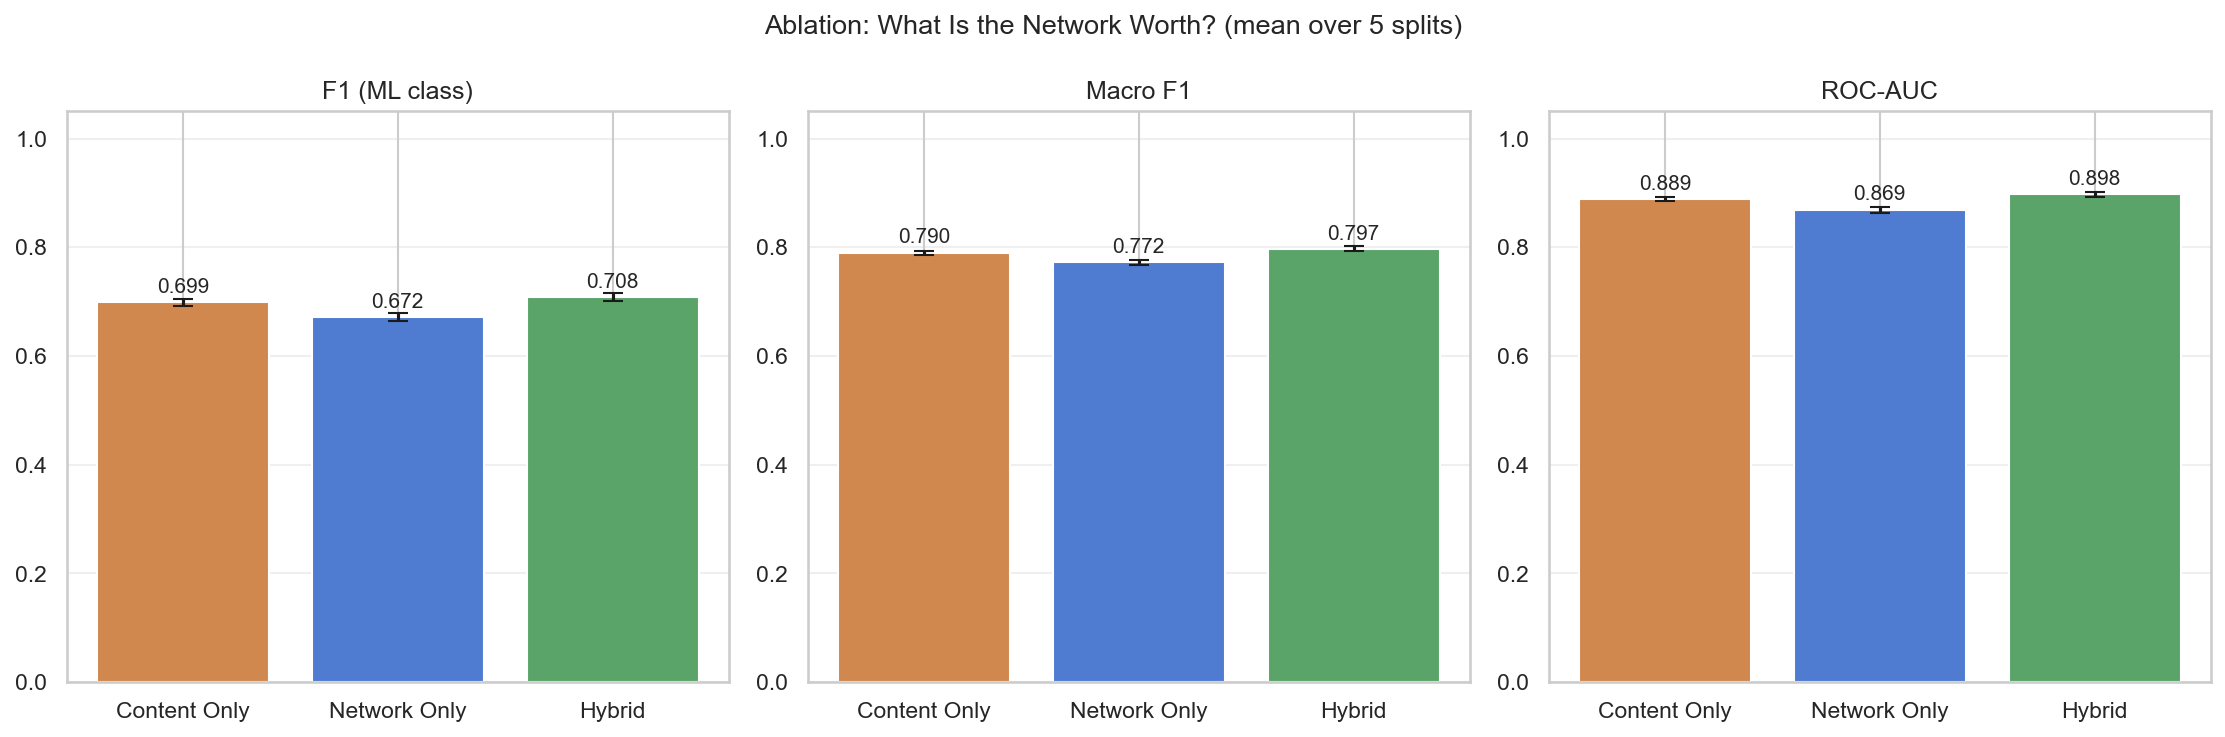

In [28]:
import pandas as pd
from IPython.display import Image, display

display(pd.read_csv(TABLES_DIR / "ablation_model_results_summary.csv").round(4))
display(Image(str(FIGURES_DIR / "ablation_f1_auc_comparison.png")))

### פרשנות

התוכן מנצח את הרשת במעט (⁦ROC-AUC⁩ ‏0.889 מול 0.869), אך ההפרש קטן: קשרי המעקב לבדם משיגים ~98% מכוח החיזוי של התוכן. ההיברידי עולה על שניהם **בכל חמש החלוקות** — כלומר הרשת מכילה מידע ייחודי שאינו קיים בתוכן. בהמשך (פרק 16) נראה שייצוג רשתי טוב יותר סוגר את הפער לחלוטין.

## 15. תת-התמחויות מפיצ'רי התוכן

התווית הבינארית ⁦Web/ML⁩ מסתירה קשת רחבה של תת-התמחויות. כאן נחלץ תת-תחומים באופן לא-מונחה: ⁦TruncatedSVD⁩ ל-64 ממדים על מטריצת התוכן, ואז ⁦KMeans⁩ (בחירת ⁦k⁩ לפי ⁦silhouette⁩). לאחר מכן נמדוד באמצעות ⁦NMI/ARI⁩ האם קהילות ה-⁦Louvain⁩ של הרשת מיושרות עם תת-התחומים או עם התווית הבינארית.

**זמן ריצה משוער: ~3 דקות.**

In [29]:
from run_subfields import main as run_subfields_main

run_subfields_main()

SVD explained variance: 0.5590
Choosing k by silhouette:


  k=4: silhouette=0.0446


  k=5: silhouette=0.0442


  k=6: silhouette=0.0462


  k=7: silhouette=0.0442


...

  k=9: silhouette=0.0469


  k=10: silhouette=0.0485
Selected k=10


 cluster  size  ml_count  ml_share
       6  4122      3184  0.772441
       0  2813      2091  0.743335
       3  3352       728  0.217184
       9  3867       774  0.200155
       1  4115       783  0.190279
       8  3151       461  0.146303
       7  5522       658  0.119160
       5  5113       604  0.118130
       2  2946       241  0.081806
       4  2699       215  0.079659


                             comparison      nmi      ari
      content_clusters_vs_binary_labels 0.098131 0.043160
   louvain_communities_vs_binary_labels 0.106123 0.062276
louvain_communities_vs_content_clusters 0.257202 0.208492


Saved tables and figures.


,comparison,nmi,ari
0,content_clusters_vs_binary_labels,0.0981,0.0432
1,louvain_communities_vs_binary_labels,0.1061,0.0623
2,louvain_communities_vs_content_clusters,0.2572,0.2085


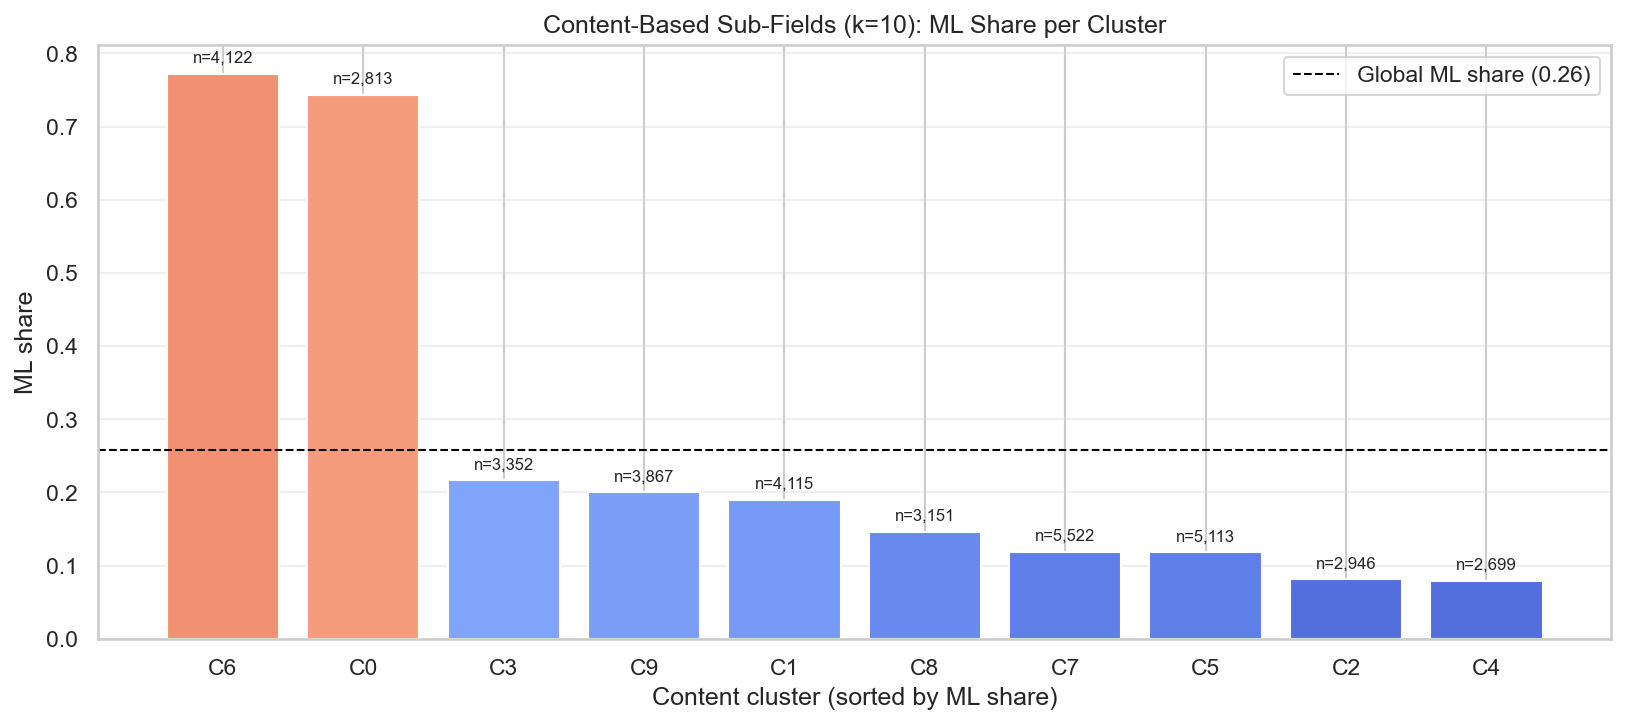

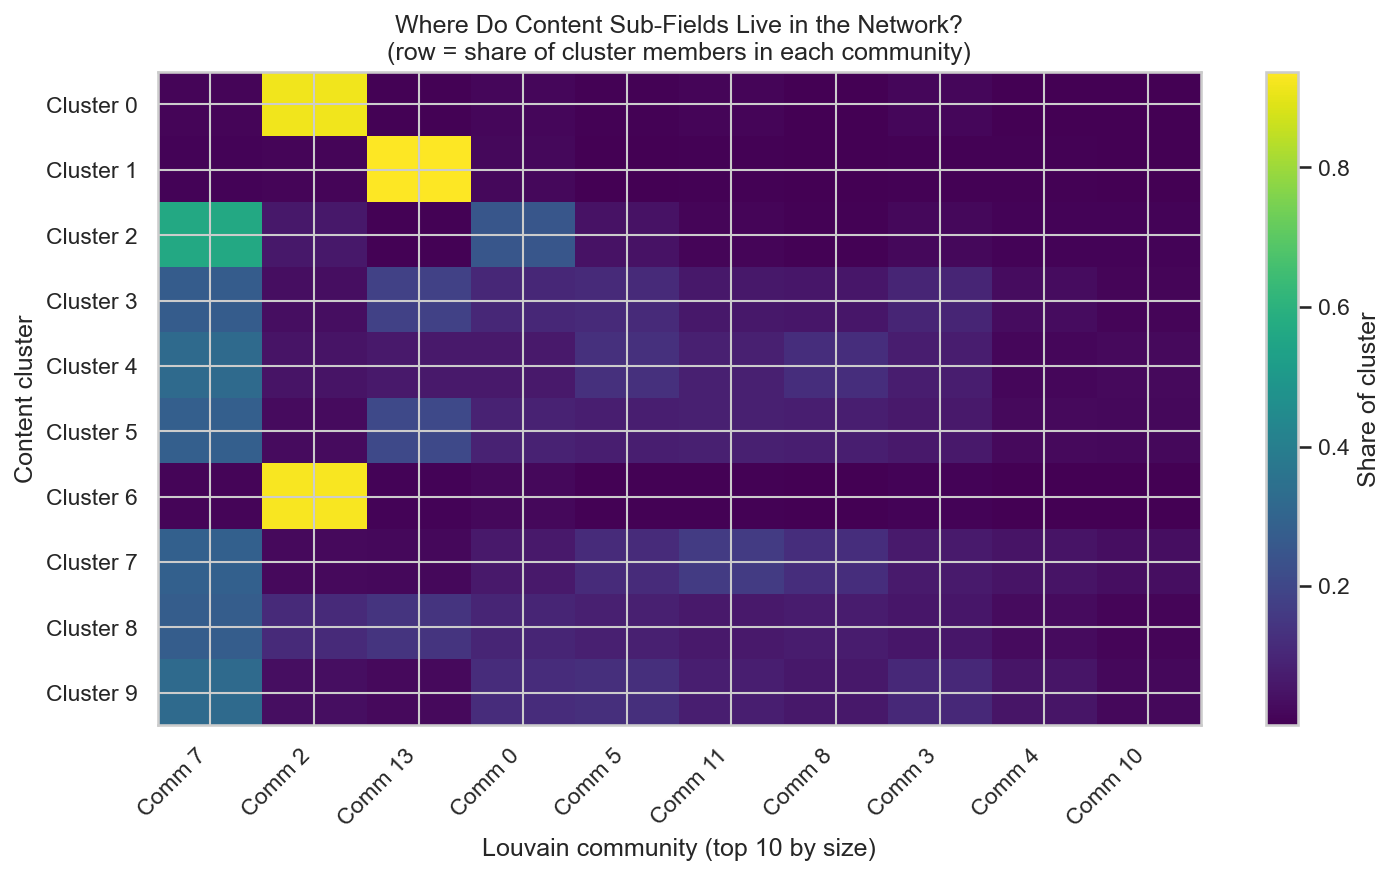

In [30]:
display(pd.read_csv(TABLES_DIR / "subfield_alignment_scores.csv").round(4))
display(Image(str(FIGURES_DIR / "subfield_ml_share.png")))
display(Image(str(FIGURES_DIR / "subfield_community_overlap.png")))

### פרשנות

קהילות הרשת מיושרות עם אשכולות התוכן (⁦NMI⁩ ‏0.257) פי ~2.4 יותר מאשר עם התווית הבינארית (⁦NMI⁩ ‏0.106): **הרשת מארגנת את עצמה סביב תת-התמחויות עדינות, לא סביב Web/ML**. שני אשכולות עתירי-⁦ML⁩ ‏(77% ו-74%) מתרכזים כמעט כולם בקהילת ה-⁦ML⁩ הדומיננטית שזוהתה בפרק 9.

*הסתייגות:* ציוני ה-⁦silhouette⁩ נמוכים (~0.05) — תת-התחומים "רכים" וחופפים; זהו ניתוח חקרני ולא קביעה על מספר תחומים אמיתי.

## 16. ייצוגים נלמדים — ⁦DeepWalk⁩ (RQ1)

⁦DeepWalk (Perozzi et al., 2014)⁩ מתייחס להילוכים אקראיים על הגרף כאל "משפטים" ולומד וקטור לכל צומת באמצעות ⁦Word2Vec skip-gram⁩ — בדיוק כמו בתרגול הקורס, על הרשת המלאה: 10 הילוכים לצומת, אורך 80, מימד 128, חלון 10.

הייצוג נלמד ללא תוויות וללא תוכן — מבנה הרשת בלבד — ולכן נשאר נאמן לעקרון ה-⁦Network-Only⁩. על הווקטורים מאומנת רגרסיה לוגיסטית באותו פרוטוקול, לבד ובשילוב הפיצ'רים הידניים.

**זמן ריצה משוער: ~15 דקות** (רובו אימון ⁦Word2Vec⁩ על ~30 מיליון צעדים).

In [31]:
from run_deepwalk import main as run_deepwalk_main

run_deepwalk_main()

Generating walks: 10 walks/node, length 80 ...


  377,000 walks in 26.0s
Training DeepWalk (dim=128, window=10, epochs=5) ...


  trained in 329.9s


Saved embeddings: C:\Dev\Graph-Algo-Course\github-social-network\outputs\embeddings\deepwalk_128.npz


[run 1/5] random_state=42


...

    Logistic Regression - DeepWalk Embeddings Only: F1=0.6990 MacroF1=0.7882 ROC-AUC=0.8922
    Logistic Regression - DeepWalk + Graph + Community Features: F1=0.7046 MacroF1=0.7915 ROC-AUC=0.9008
[run 3/5] random_state=21


    Logistic Regression - DeepWalk Embeddings Only: F1=0.6870 MacroF1=0.7815 ROC-AUC=0.8802
    Logistic Regression - DeepWalk + Graph + Community Features: F1=0.6943 MacroF1=0.7861 ROC-AUC=0.8915
[run 4/5] random_state=84


    Logistic Regression - DeepWalk Embeddings Only: F1=0.7054 MacroF1=0.7942 ROC-AUC=0.8932
    Logistic Regression - DeepWalk + Graph + Community Features: F1=0.7125 MacroF1=0.7983 ROC-AUC=0.9052
[run 5/5] random_state=123


    Logistic Regression - DeepWalk Embeddings Only: F1=0.6964 MacroF1=0.7874 ROC-AUC=0.8875
    Logistic Regression - DeepWalk + Graph + Community Features: F1=0.7031 MacroF1=0.7919 ROC-AUC=0.8977
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\deepwalk_model_results.csv
Computing t-SNE ...


Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\deepwalk_tsne.png
Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\deepwalk_comparison.png

=== Summary (mean over splits) ===
                                                      model  f1_mean  macro_f1_mean  roc_auc_mean
Logistic Regression - DeepWalk + Graph + Community Features 0.701782       0.790591      0.897835
             Logistic Regression - DeepWalk Embeddings Only 0.694855       0.786298      0.887249


,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,roc_auc_mean,roc_auc_std
0,Logistic Regression - DeepWalk + Graph + Commu...,0.8283,0.0043,0.8133,0.0061,0.6364,0.0072,0.7822,0.0117,0.7018,0.0077,0.7906,0.0053,0.8335,0.0042,0.8978,0.0054
1,Logistic Regression - DeepWalk Embeddings Only,0.8254,0.0048,0.8072,0.0061,0.6336,0.0083,0.7693,0.0108,0.6949,0.0080,0.7863,0.0057,0.8305,0.0045,0.8872,0.0056


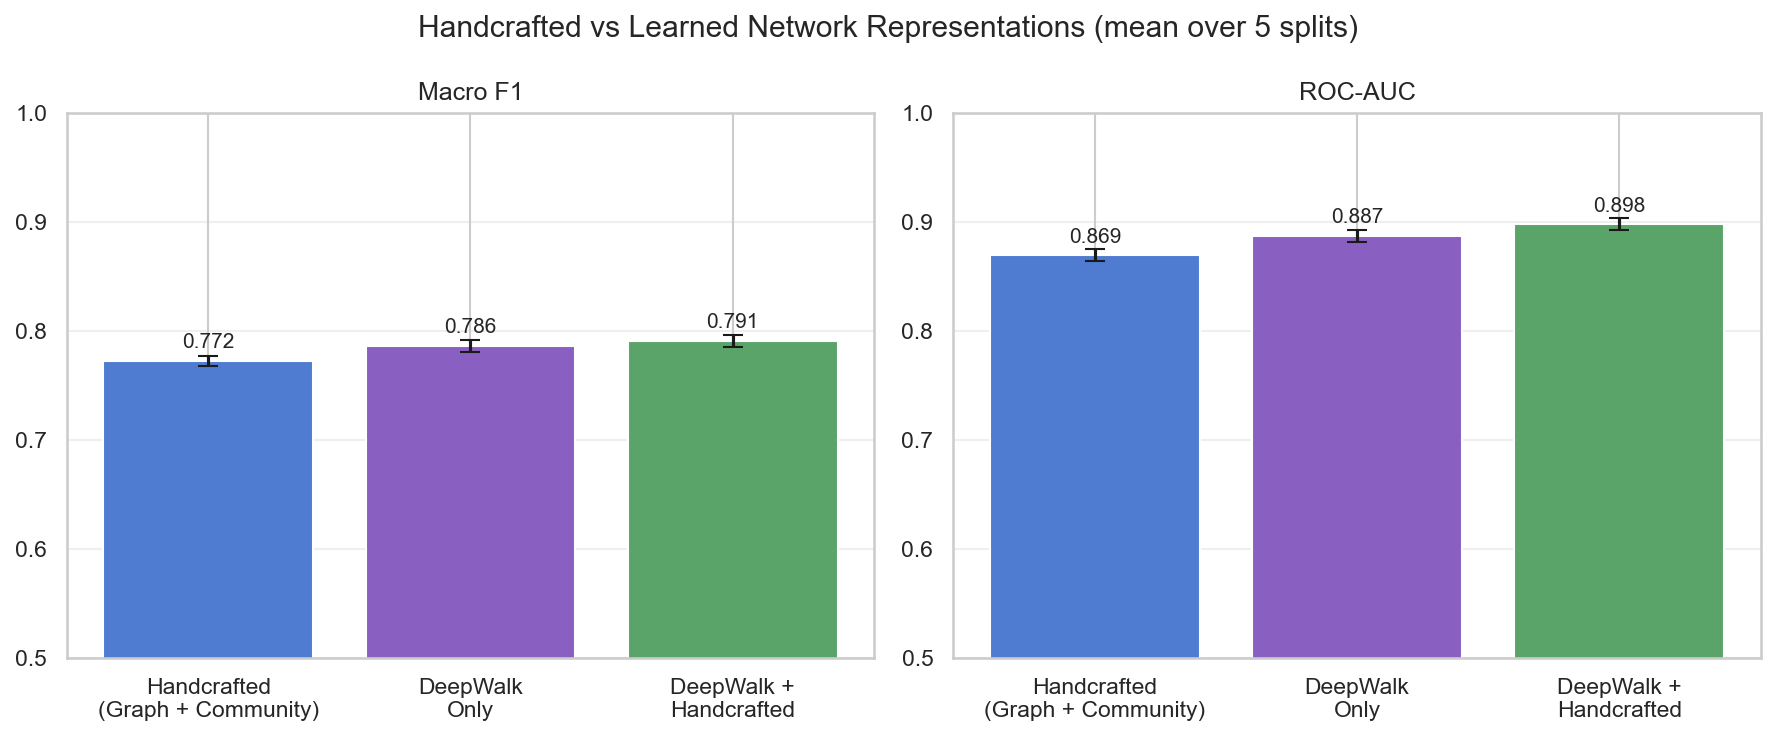

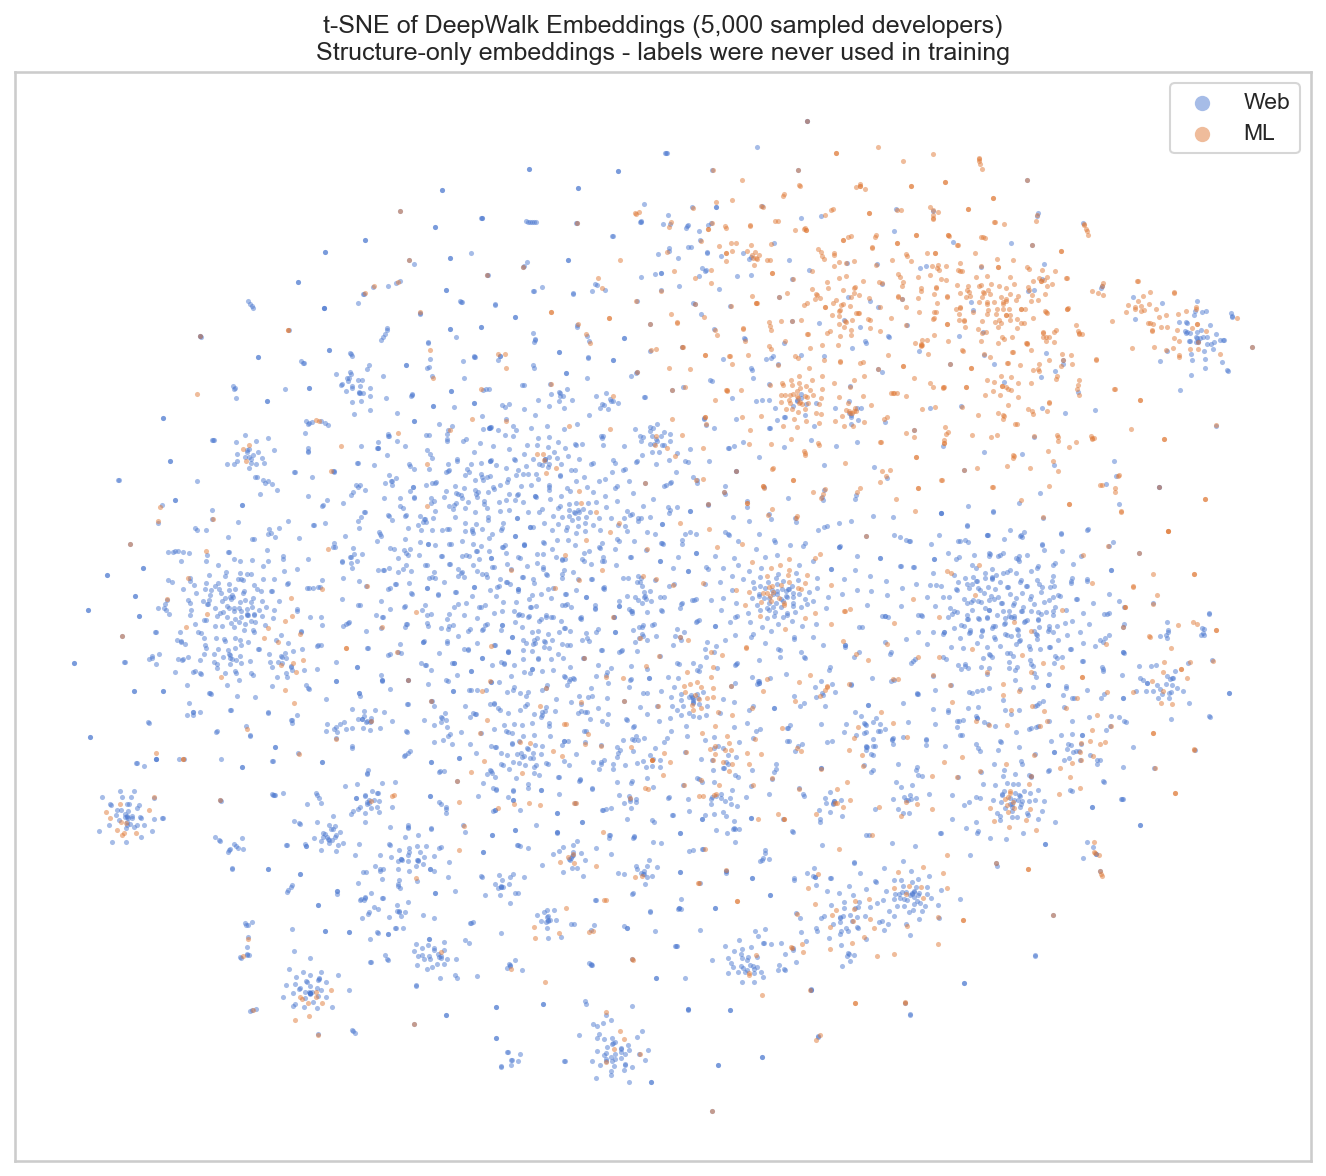

In [32]:
display(pd.read_csv(TABLES_DIR / "deepwalk_model_results_summary.csv").round(4))
display(Image(str(FIGURES_DIR / "deepwalk_comparison.png")))
display(Image(str(FIGURES_DIR / "deepwalk_tsne.png")))

### פרשנות

⁦DeepWalk⁩ לבדו (⁦AUC⁩ ‏0.888) עוקף את כל הפיצ'רים הידניים (0.869) ומשתווה סטטיסטית לתוכן (0.889, ‏⁦p=0.62⁩ במבחן זוגי — ראו פרק 20): **הפער בין רשת לתוכן היה בעיית ייצוג, לא חוסר מידע**. מפת ה-⁦t-SNE⁩ מראה את אזור ה-⁦ML⁩ מתגבש מעצמו, אף שהאימון מעולם לא ראה תווית.

## 17. רשת נוירונים גרפית — ⁦GCN⁩ (RQ1)

⁦GCN (Kipf & Welling, 2017)⁩: כל שכבה מערבבת את ייצוג הצומת עם ייצוגי שכניו על גבי מטריצת השכנות המנורמלת — ⁦H' = ReLU(A_hat @ H @ W)⁩. שתי שכבות = שדה ראייה עד מרחק 2. המימוש ב-⁦PyTorch⁩ טהור (ללא ⁦PyTorch Geometric⁩) עם מטריצה דלילה, כך שהגרף המלא מתאמן על ⁦CPU⁩.

שתי גרסאות קלט: (א) 5 פיצ'רים מבניים בסיסיים; (ב) 128 ממדי ⁦DeepWalk⁩ (דורש שפרק 16 ירוץ קודם). בחירת ⁦epoch⁩ מיטבי על ⁦validation⁩ פנימי (10% מה-⁦train⁩) — תוויות ה-⁦test⁩ אינן נקראות באימון.

**זמן ריצה משוער: ~30 דקות.**

In [33]:
from run_gnn import main as run_gnn_main

run_gnn_main()

Building normalized adjacency ...


Computing structural input features ...


[run 1/5] random_state=42


    GCN - Structural Input: F1=0.5879 MacroF1=0.6902 ROC-AUC=0.8126 (82s)


    GCN - DeepWalk Input: F1=0.6973 MacroF1=0.7874 ROC-AUC=0.8915 (132s)
[run 2/5] random_state=7


...

    GCN - Structural Input: F1=0.5874 MacroF1=0.6865 ROC-AUC=0.8229 (80s)


    GCN - DeepWalk Input: F1=0.7123 MacroF1=0.7979 ROC-AUC=0.9025 (132s)
[run 5/5] random_state=123


    GCN - Structural Input: F1=0.5758 MacroF1=0.6727 ROC-AUC=0.8202 (80s)


    GCN - DeepWalk Input: F1=0.7035 MacroF1=0.7909 ROC-AUC=0.8970 (133s)



=== Summary (mean over splits) ===
                 model  f1_mean  macro_f1_mean  roc_auc_mean
  GCN - DeepWalk Input 0.703242       0.791314      0.896082
GCN - Structural Input 0.580034       0.679076      0.816036
Saved tables and figure.


,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,roc_auc_mean,roc_auc_std
0,GCN - DeepWalk Input,0.8285,0.0033,0.8149,0.0052,0.6359,0.0061,0.7867,0.0119,0.7032,0.0061,0.7913,0.0040,0.8339,0.0032,0.8961,0.0049
1,GCN - Structural Input,0.7097,0.0105,0.7312,0.0063,0.4634,0.0111,0.7757,0.0157,0.5800,0.0077,0.6791,0.0086,0.7269,0.0094,0.8160,0.0055


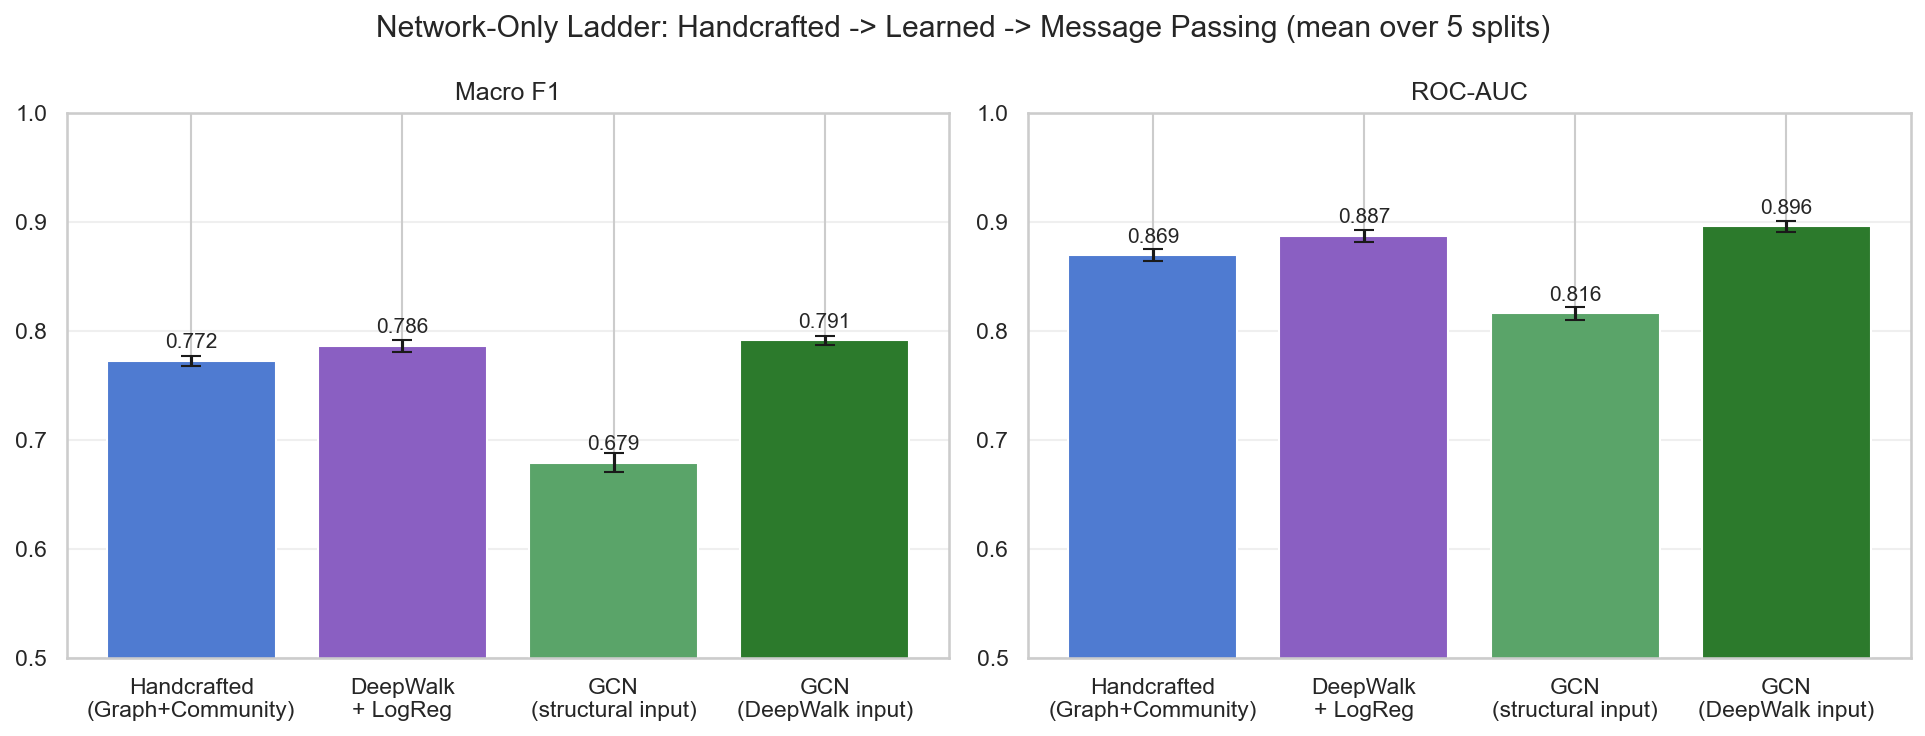

In [34]:
display(pd.read_csv(TABLES_DIR / "gnn_model_results_summary.csv").round(4))
display(Image(str(FIGURES_DIR / "gnn_network_only_ladder.png")))

### פרשנות

שני ממצאים: (1) **איכות הייצוג חשובה מהארכיטקטורה** — ⁦GCN⁩ עם קלט מבני דל (0.816) נופל מהמודל הידני, אך אותו ⁦GCN⁩ עם קלט ⁦DeepWalk⁩ מגיע ל-0.896; (2) **תקרת ביצועים** — שלושת המודלים החזקים (⁦DeepWalk⁩+ידני 0.899, ‏⁦GCN⁩ 0.896, היברידי 0.898) שקולים סטטיסטית, מה שמרמז שהחסם הוא רעש התוויות (שנגזרו מכותרות תפקיד) ולא מגבלת מידע ברשת.

*הערת הגינות:* המודל הידני נעזר גם בפיצ'רי תוויות-שכנים, בעוד ה-⁦GCN⁩ רואה תוויות רק דרך פונקציית ההפסד — זה חלק מההסבר לפער מול הקלט המבני.

## 18. חיזוי קשרים — ⁦Link Prediction⁩ (RQ3)

מסתירים 10% מהקשתות, דוגמים זוגות לא-מחוברים כמותם, ובוחנים חמש היוריסטיקות קלאסיות (⁦Liben-Nowell & Kleinberg, 2003⁩): ⁦Common Neighbors⁩, ⁦Jaccard⁩, ⁦Adamic-Adar⁩, ⁦Preferential Attachment⁩ ואינדיקטור ⁦Same-Community⁩. כל החישובים — כולל ⁦Louvain⁩ — על גרף האימון בלבד.

השאלה המקורית: האם קשתות תוך-תחומיות (⁦Web-Web⁩, ⁦ML-ML⁩) צפויות יותר מקשתות חוצות-תחום?

**זמן ריצה משוער: ~2 דקות.**

In [35]:
from run_link_prediction import main as run_link_prediction_main

run_link_prediction_main()

[run 1/5] seed=42


  hidden 28,900 edges; train graph: 260,103 edges, 571 components


  done in 9.7s
[run 2/5] seed=7


  hidden 28,900 edges; train graph: 260,103 edges, 563 components


  done in 9.8s
[run 3/5] seed=21


...

  hidden 28,900 edges; train graph: 260,103 edges, 602 components


  done in 8.6s
[run 5/5] seed=123


  hidden 28,900 edges; train graph: 260,103 edges, 554 components


  done in 9.5s



=== Overall summary (mean over splits) ===
       heuristic  roc_auc_mean  roc_auc_std  average_precision_mean  average_precision_std
     Adamic-Adar      0.845988     0.000985                0.855435               0.000941
Common Neighbors      0.839679     0.001073                0.836937               0.001007
         Jaccard      0.794926     0.001408                0.718961               0.002126
Pref. Attachment      0.909830     0.001563                0.926664               0.001113
  Same Community      0.690170     0.005961                0.650635               0.004435

=== By edge type (ROC-AUC mean) ===
edge_type            ML-ML    Web-ML   Web-Web
heuristic                                     
Adamic-Adar       0.766998  0.803120  0.857836
Common Neighbors  0.762577  0.798139  0.850383
Jaccard           0.749428  0.774086  0.788166
Pref. Attachment  0.848735  0.890287  0.917725
Same Community    0.716665  0.699351  0.678291

Saved tables and figures.


,heuristic,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std
0,Adamic-Adar,0.8460,0.0010,0.8554,0.0009
1,Common Neighbors,0.8397,0.0011,0.8369,0.0010
2,Jaccard,0.7949,0.0014,0.7190,0.0021
3,Pref. Attachment,0.9098,0.0016,0.9267,0.0011
4,Same Community,0.6902,0.0060,0.6506,0.0044


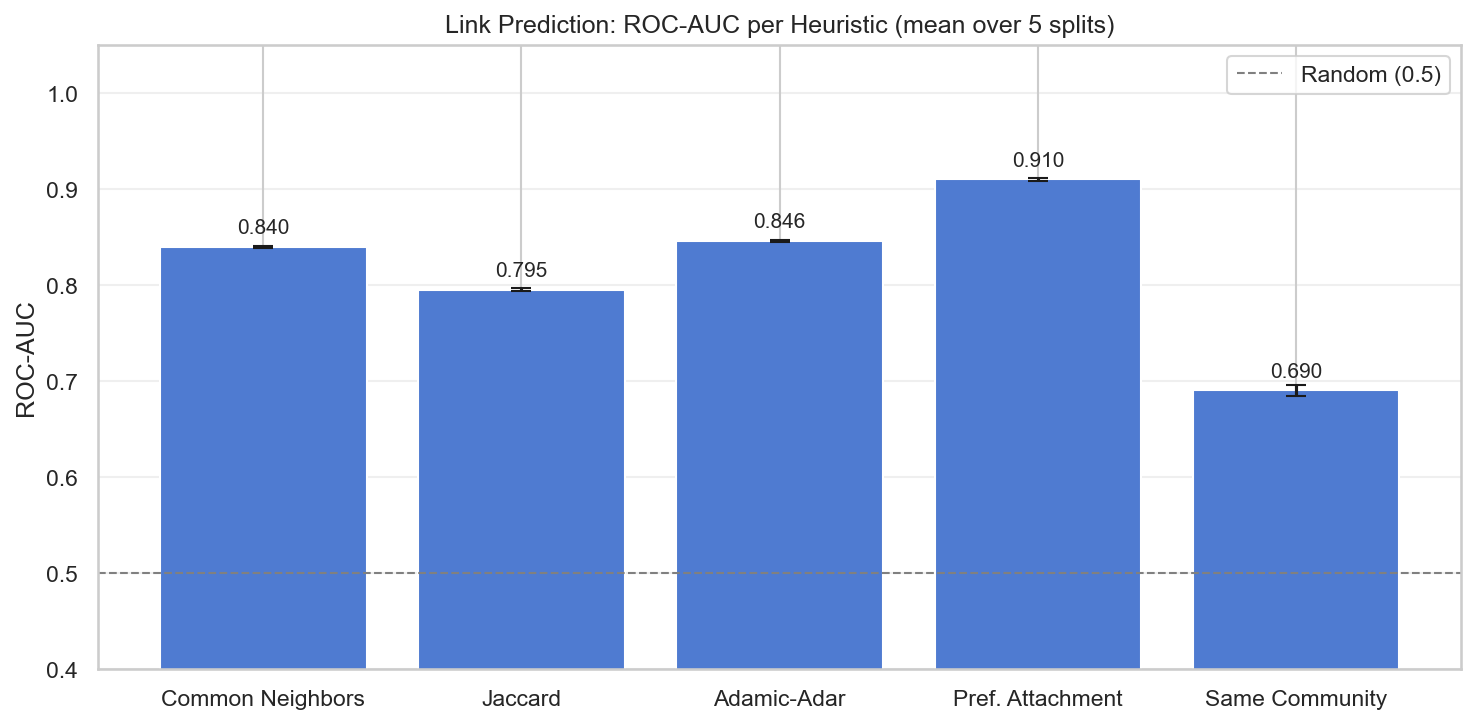

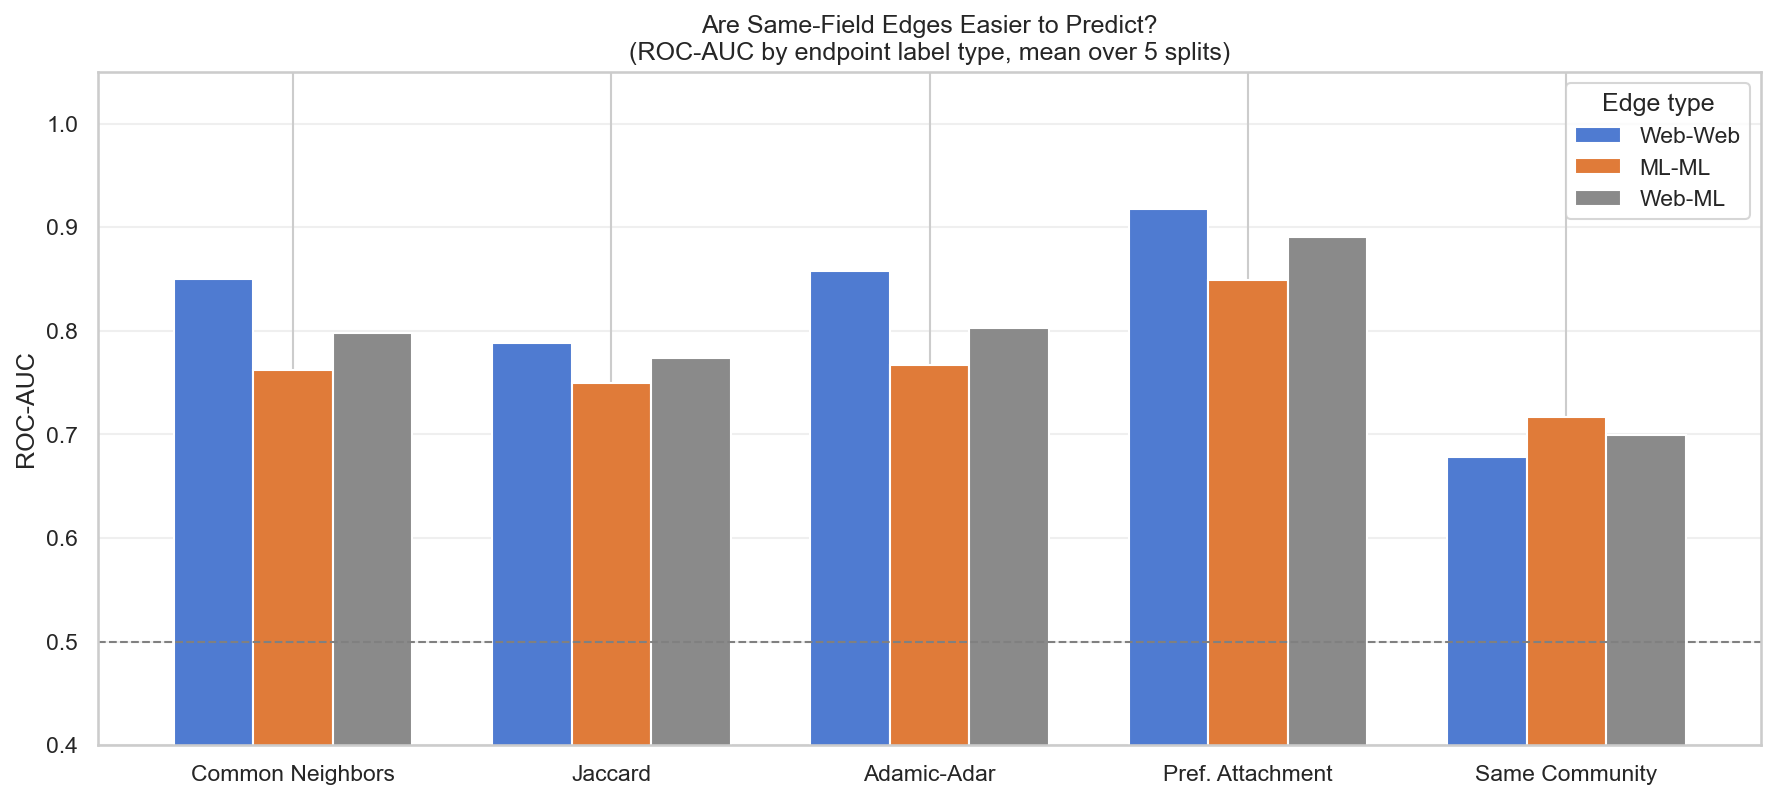

In [36]:
display(pd.read_csv(TABLES_DIR / "link_prediction_results_summary.csv").round(4))
display(Image(str(FIGURES_DIR / "link_prediction_auc.png")))
display(Image(str(FIGURES_DIR / "link_prediction_by_edge_type.png")))

### פרשנות

⁦Preferential Attachment⁩ מוביל (⁦AUC⁩ ‏0.910) — עקבי עם הזנב הכבד של הרשת (פרק 19). ההשערה **הופרכה**: הסדר הוא ⁦Web-Web⁩ > ⁦Web-ML⁩ > ⁦ML-ML⁩ — החיזוי עוקב אחרי צפיפות שכונתית ולא אחרי דמיון תוויות; שכונות ה-⁦ML⁩ הדלילות קשות יותר לחיזוי. היוריסטיקה היחידה שמתהפכת היא ⁦Same-Community⁩ ‏(⁦ML-ML⁩ ‏0.717 > ⁦Web-Web⁩ ‏0.678) — עקבי עם קהילת ⁦ML⁩ דומיננטית אחת.

## 19. מודלים אקראיים ומובהקות מבנית (RQ4)

שלוש בדיקות מול מודלי אפס:

1. **הומופיליה:** הערך הנצפה (84.5% קשתות ⁦same-label⁩) מול (א) 1,000 ערבובי תוויות; (ב) 10 גרפים מעורבלים משמרי-דרגות (⁦double edge swap⁩).
2. **מודולריות:** ‏⁦Louvain⁩ על הגרפים המעורבלים.
3. **אפיון מול מודלים קלאסיים:** השוואה ל-⁦Erdős–Rényi⁩ ו-⁦Barabási–Albert⁩ באותו גודל, והתאמת חוק חזקה (⁦powerlaw, Clauset et al. 2009⁩) עם מבחני יחס נראות.

**זמן ריצה משוער: ~30 דקות** (רובו ערבול הקשתות ו-⁦Louvain⁩ החוזר).

In [37]:
from run_null_models import main as run_null_models_main

run_null_models_main()

Observed same-label fraction: 0.8453
Observed label assortativity: 0.3778
Null A: 1000 label shuffles ...


  done in 1.4s
Null B: 10 degree-preserving rewired graphs ...


  rewire 1/10: same-label=0.7609, modularity=0.1883 (25s)


  rewire 2/10: same-label=0.7613, modularity=0.1877 (18s)


  rewire 3/10: same-label=0.7603, modularity=0.1886 (18s)


...

  Erdos-Renyi done (57s)


  Barabasi-Albert (m=8) done (55s)
              network  nodes  edges  max_degree  mean_degree  transitivity  avg_clustering  degree_assortativity  avg_shortest_path_sampled
               GitHub  37700 289003        9458    15.331724      0.012357        0.167537             -0.075217                   3.217995
          Erdos-Renyi  37700 289003          34    15.331724      0.000394        0.000396              0.001112                   4.125327
Barabasi-Albert (m=8)  37700 301536         891    15.996605      0.002709        0.003378             -0.013764                   3.589527
Fitting power law to the degree distribution ...


C:\Users\ofir8\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\powerlaw\distributions.py:776: UserWarning: No valid fits found for distribution lognormal.
  warnings.warn(f"No valid fits found for distribution {self.name}.")


   alpha  xmin    sigma  loglik_ratio_vs_lognormal  p_vs_lognormal  loglik_ratio_vs_exponential  p_vs_exponential
2.544116  55.0 0.037774                   0.012701        0.782626                   605.791061      2.128203e-07


Saved tables and figures.


,null_model,n_samples,observed,null_mean,null_std,z_score,empirical_p
0,label_shuffle,1000,0.8453,0.6166,0.0118,19.4422,0.0
1,degree_preserving_rewire,10,0.8453,0.7606,0.0004,196.9124,0.0


,network,nodes,edges,max_degree,mean_degree,transitivity,avg_clustering,degree_assortativity,avg_shortest_path_sampled
0,GitHub,37700,289003,9458,15.3317,0.0124,0.1675,-0.0752,3.2180
1,Erdos-Renyi,37700,289003,34,15.3317,0.0004,0.0004,0.0011,4.1253
2,Barabasi-Albert (m=8),37700,301536,891,15.9966,0.0027,0.0034,-0.0138,3.5895


,alpha,xmin,sigma,loglik_ratio_vs_lognormal,p_vs_lognormal,loglik_ratio_vs_exponential,p_vs_exponential
0,2.5441,55.0,0.0378,0.0127,0.7826,605.7911,0.0


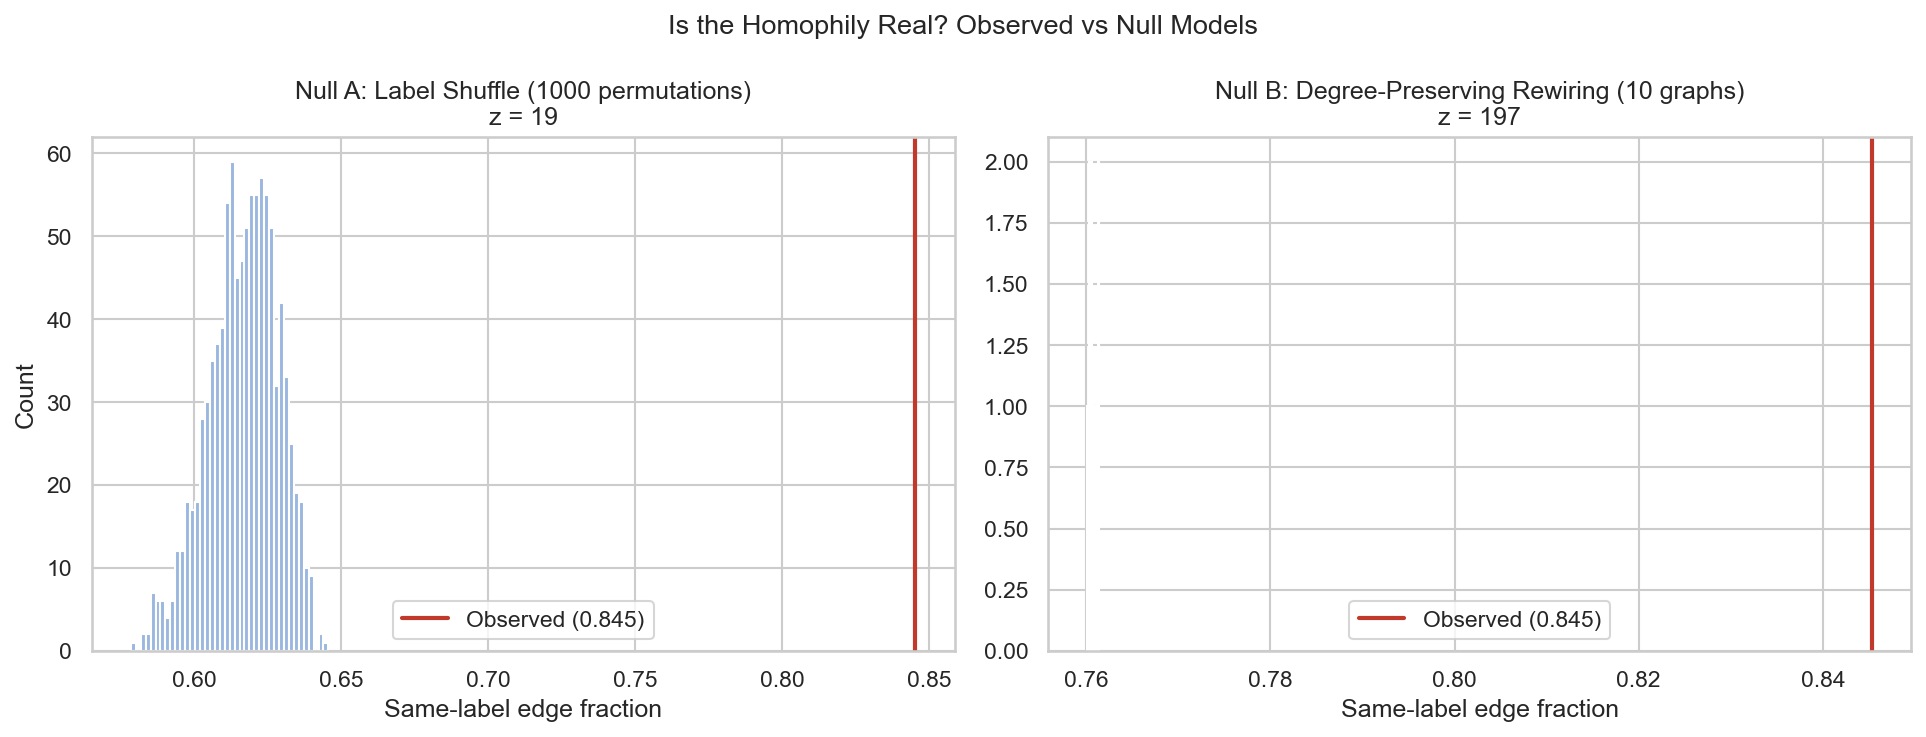

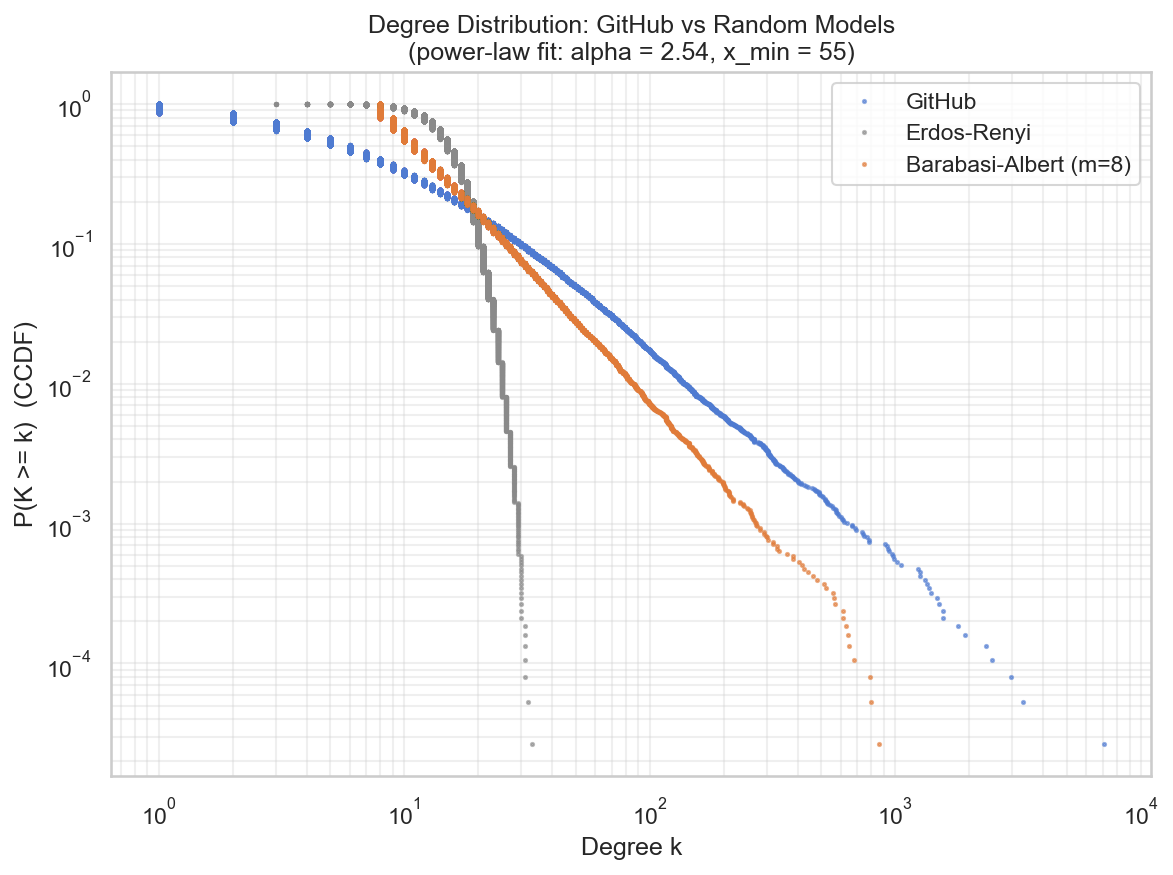

In [38]:
display(pd.read_csv(TABLES_DIR / "null_model_homophily.csv").round(4))
display(pd.read_csv(TABLES_DIR / "network_vs_random_models.csv").round(4))
display(pd.read_csv(TABLES_DIR / "powerlaw_fit.csv").round(4))
display(Image(str(FIGURES_DIR / "homophily_null_distribution.png")))
display(Image(str(FIGURES_DIR / "degree_distribution_loglog.png")))

### פרשנות

ההומופיליה מובהקת בשני מודלי האפס (⁦z=19⁩ ו-⁦z=197⁩), אך הפער ביניהם מלמד: תחת ערבול משמר-דרגות הצפי הוא 76.1% (ולא 61.7%), כי מפתחי ⁦Web⁩ מחזיקים ~87% מקצוות הקשתות. כלומר כשני שליש מההומופיליה הגולמית מוסברים בהבדלי דרגות, ונותרת העדפה תוך-תחומית אמיתית של ~8.5 נקודות. המודולריות (0.453 מול 0.189, ‏⁦z=304⁩) מובהקת אף היא.

הרשת היא ⁦Small-World⁩ מובהק (התקבצות פי ~420 מ-⁦ER⁩, מרחק ממוצע 3.2) עם זנב כבד: חוק חזקה ⁦α=2.54⁩ עדיף מובהק על מעריכית (⁦p≈2×10⁻⁷⁩) אך אינו ניתן להבחנה מלוג-נורמלית (⁦p=0.78⁩) — בהתאם ל-⁦Broido & Clauset (2019)⁩ ננסח "כבדת-זנב" ולא "⁦scale-free⁩ מוכח".

## 20. מבחני מובהקות זוגיים

כל הניסויים רצים על אותן 5 חלוקות, ולכן ניתן להשוות מודלים במבחן ⁦t⁩ זוגי על ההפרשים פר-חלוקה, עם רווחי סמך 95%. ⁦Wilcoxon⁩ מדווח כתמיכה בלבד (עם 5 חלוקות ערכו המזערי הוא ⁦p=0.0625⁩).

**זמן ריצה: שניות** (עובד על קובצי התוצאות השמורים; דורש שכל הפרקים הקודמים רצו).

In [39]:
from run_significance import main as run_significance_main

run_significance_main()

Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\tables\significance_tests.csv

                          comparison   metric  mean_diff  ci95_low  ci95_high  t_pvalue  wilcoxon_pvalue
                Neighbor vs Majority       f1     0.5165    0.5031     0.5298    0.0000           0.0625
                Neighbor vs Majority macro_f1     0.2767    0.2689     0.2844    0.0000           0.0625
                Neighbor vs Majority  roc_auc     0.2851    0.2785     0.2917    0.0000           0.0625
               LabelProp vs Neighbor       f1     0.0352    0.0267     0.0437    0.0003           0.0625
               LabelProp vs Neighbor macro_f1     0.0203    0.0156     0.0250    0.0003           0.0625
               LabelProp vs Neighbor  roc_auc     0.0170    0.0114     0.0225    0.0011           0.0625
              GraphFeat vs LabelProp       f1     0.0854    0.0763     0.0945    0.0000           0.0625
              GraphFeat vs LabelProp macro_f1     0.0284    0.0224 


Saved: C:\Dev\Graph-Algo-Course\github-social-network\outputs\figures\significance_forest_plot.png


,comparison,baseline_model,improved_model,metric,n_splits,mean_diff,std_diff,ci95_low,ci95_high,t_statistic,t_pvalue,wilcoxon_pvalue
0,Neighbor vs Majority,Majority Baseline,Neighbor Majority,f1,5,0.5165,0.0107,0.5031,0.5298,107.5164,0.0000,0.0625
1,Neighbor vs Majority,Majority Baseline,Neighbor Majority,macro_f1,5,0.2767,0.0063,0.2689,0.2844,98.8839,0.0000,0.0625
2,Neighbor vs Majority,Majority Baseline,Neighbor Majority,roc_auc,5,0.2851,0.0054,0.2785,0.2917,119.1489,0.0000,0.0625
3,LabelProp vs Neighbor,Neighbor Majority,Label Propagation,f1,5,0.0352,0.0068,0.0267,0.0437,11.5549,0.0003,0.0625
4,LabelProp vs Neighbor,Neighbor Majority,Label Propagation,macro_f1,5,0.0203,0.0038,0.0156,0.0250,11.9743,0.0003,0.0625
5,LabelProp vs Neighbor,Neighbor Majority,Label Propagation,roc_auc,5,0.0170,0.0045,0.0114,0.0225,8.4397,0.0011,0.0625
6,GraphFeat vs LabelProp,Label Propagation,Logistic Regression - Graph Features Only,f1,5,0.0854,0.0073,0.0763,0.0945,26.0349,0.0000,0.0625
7,GraphFeat vs LabelProp,Label Propagation,Logistic Regression - Graph Features Only,macro_f1,5,0.0284,0.0049,0.0224,0.0345,13.0899,0.0002,0.0625
8,GraphFeat vs LabelProp,Label Propagation,Logistic Regression - Graph Features Only,roc_auc,5,0.0390,0.0074,0.0298,0.0482,11.7405,0.0003,0.0625
9,+Community vs GraphFeat,Logistic Regression - Graph Features Only,Logistic Regression - Graph + Community Features,f1,5,0.0345,0.0050,0.0283,0.0406,15.5442,0.0001,0.0625


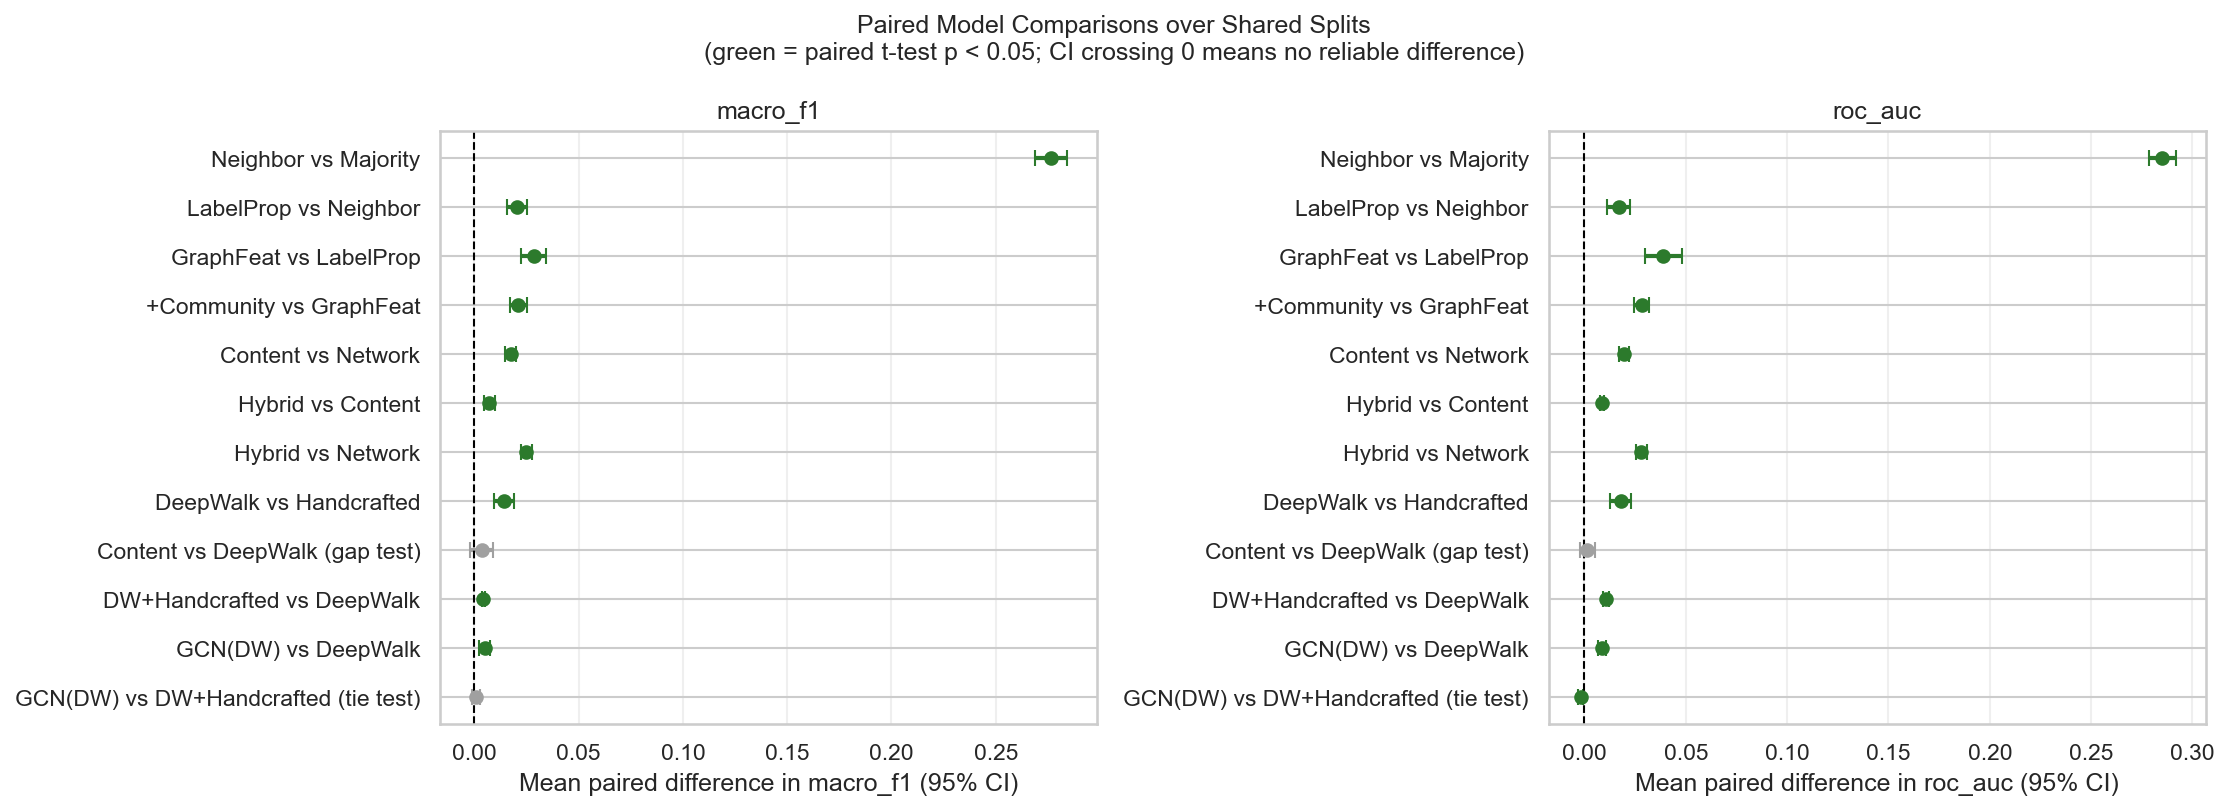

In [40]:
display(pd.read_csv(TABLES_DIR / "significance_tests.csv").round(4))
display(Image(str(FIGURES_DIR / "significance_forest_plot.png")))

### פרשנות

כל מעברי הסולם מובהקים (⁦p<0.002⁩) ואף רווח סמך אינו חוצה אפס — כל שכבת מידע תורמת תרומה אמיתית. שני מבחנים ראויים לציון: מבחן "סגירת הפער" (⁦Content vs DeepWalk⁩) אינו מובהק (⁦p=0.62⁩ ב-⁦AUC⁩) — הרשת שקולה לתוכן; ומבחן ה"תיקו" בפסגה (⁦GCN⁩ מול ⁦DeepWalk⁩+ידני, ⁦p=0.85⁩) מאשש את קיומה של תקרת ביצועים משותפת סביב ⁦AUC≈0.90⁩.

## 21. דיון בתוצאות

### סולם המודלים המלא (ממוצע על 5 חלוקות)

| מודל | F1 | Macro F1 | ROC-AUC |
|---|---:|---:|---:|
| ⁦Majority Baseline⁩ | 0.000 | 0.426 | 0.500 |
| ⁦Neighbor Majority⁩ | 0.517 | 0.703 | 0.785 |
| ⁦Label Propagation⁩ | 0.552 | 0.723 | 0.802 |
| ⁦LogReg — Graph Features⁩ | 0.637 | 0.751 | 0.841 |
| ⁦LogReg — Graph + Community⁩ | 0.671 | 0.772 | 0.869 |
| ⁦GCN — Structural Input⁩ | 0.580 | 0.679 | 0.816 |
| ⁦LogReg — DeepWalk⁩ | 0.694 | 0.786 | 0.888 |
| ⁦LogReg — Content Only⁩ | 0.699 | 0.790 | 0.889 |
| ⁦GCN — DeepWalk Input⁩ | 0.704 | 0.792 | 0.896 |
| ⁦LogReg — DeepWalk + Handcrafted⁩ | 0.704 | 0.792 | **0.899** |
| ⁦LogReg — Hybrid (Network + Content)⁩ | **0.708** | **0.797** | 0.898 |

כל מעברי הסולם מובהקים במבחן ⁦t⁩ זוגי (⁦p<0.002⁩, פרק 20), ואף רווח סמך אינו חוצה אפס.

### שלוש מסקנות רוחביות

1. **ייצוג חשוב יותר מארכיטקטורה:** ⁦GCN⁩ עם קלט מבני דל (0.816) נופל מפיצ'רים ידניים (0.869), אך אותו ⁦GCN⁩ עם קלט ⁦DeepWalk⁩ מגיע ל-0.896. השאלה המכרעת אינה "איזה מודל" אלא "איזה ייצוג".
2. **מבנה הרשת שקול לתוכן:** ⁦DeepWalk⁩ (רשת בלבד, 0.888) אינו ניתן להבחנה סטטיסטית מפיצ'רי תוכן (0.889, ⁦p=0.62⁩). הפער שנצפה בניסוי ה-⁦Ablation⁩ מול הפיצ'רים הידניים היה בעיית ייצוג — לא חוסר מידע ברשת.
3. **תקרת ביצועים משותפת:** שלושה מודלים שונים מהותית (⁦DeepWalk⁩+ידני, ⁦GCN⁩, היברידי רשת+תוכן) מתכנסים ל-⁦ROC-AUC⁩ ‏0.896–0.899 ושקולים סטטיסטית. התקרה משקפת ככל הנראה רעש בתוויות (שנגזרו מכותרות תפקיד) ולא מגבלת מידע.

### ממצאים משלימים

- **כיול סף** (פרקים 11–12): המשקולות המאזנות ייתרו ברובן את הכיול; העלאת הסף ל-0.65 שיפרה ⁦Precision⁩ תוך שמירת ⁦Recall⁩.
- **חיזוי קשתות** (פרק 18): ⁦Preferential Attachment⁩ מוביל (⁦AUC⁩ ‏0.910); צפיפות שכונתית — לא דמיון תוויות — היא הגורם המסביר את חיזוי הקשרים.
- **הומופיליה מפורקת** (פרק 19): כשני שליש מה-84.5% מוסברים בהבדלי דרגות בין המחלקות; העודף (~8.5 נק') הוא העדפה תוך-תחומית אמיתית ומובהקת (⁦z=197⁩).
- **תת-התמחויות** (פרק 15): קהילות הרשת עוקבות אחרי תת-תחומי תוכן (⁦NMI⁩ ‏0.257) הרבה יותר מאשר אחרי התווית הבינארית (0.106) — המשימה הבינארית היא רצפה, לא תקרה, של המידע ברשת.

## 22. מגבלות העבודה
- הדאטה הוא מיוני 2019 ולכן אינו מייצג בהכרח את ⁦GitHub⁩ כיום.
- המשימה בינארית בלבד: ⁦Web⁩ מול ⁦Machine Learning⁩; ניתוח תת-ההתמחויות (פרק 15) ממתן מגבלה זו אך אינו מחליף תוויות רב-מחלקתיות אמיתיות.
- התוויות נגזרו מתיאורי תפקידים ועלולות לכלול רעש — תקרת הביצועים המשותפת (~⁦AUC 0.90⁩) עקבית עם השערה זו.
- הגרף סטטי ואינו כולל התפתחות בזמן.
- עומס חישובי ברשתות ענק: מדדי מרכזיות גלובליים (⁦Betweenness⁩) חושבו בקירוב מבוסס-מדגם.
- עם 5 חלוקות, מבחן ⁦Wilcoxon⁩ מוגבל ל-⁦p≥0.0625⁩; מבחן ה-⁦t⁩ הזוגי הוא המבחן הראשי.
- אשכולות התוכן "רכים" (⁦silhouette⁩ ‏~0.05, ‏⁦k⁩ בקצה הטווח שנבדק) — ניתוח חקרני בלבד.
- התפלגות הדרגות אינה ניתנת להבחנה מלוג-נורמלית, ולכן נמנענו מהכרזת "⁦scale-free⁩" גורפת.
- נבחן ⁦GCN⁩ יחיד בכוונון בסיסי, ללא ⁦GraphSAGE⁩/⁦GAT⁩ או חיפוש היפר-פרמטרים נרחב.

## 23. מסקנות

תשובות לארבע שאלות המחקר:

- **RQ1 — חיזוי צמתים:** ניתן לחזות את תחום ההתמחות מקשרי מעקב בלבד, ומדרג המודלים מובהק בכל שלב: שכנות < הפצת תוויות < פיצ'רים גרפיים < קהילות < ייצוגים נלמדים. המודלים הרשתיים החזקים ביותר הם ⁦DeepWalk⁩+ידני ו-⁦GCN⁩ עם קלט ⁦DeepWalk⁩ ‏(⁦ROC-AUC⁩ ‏≈0.90).
- **RQ2 — רשת מול תוכן:** בייצוג מספיק חזק, מבנה הרשת לבדו שקול סטטיסטית למאפייני התוכן ("תגיד לי אחרי מי אתה עוקב — ואומר לך מה תחומך"). ההיברידי מוסיף שיפור קטן אך מובהק — לרשת ולתוכן חפיפת מידע גבוהה אך לא מלאה.
- **RQ3 — חיזוי קשתות:** קשרי המעקב ניתנים לחיזוי (⁦AUC⁩ ‏0.910 עם ⁦Preferential Attachment⁩). ההשערה שקשרים תוך-תחומיים צפויים יותר הופרכה: צפיפות שכונתית היא הגורם המסביר, ושכונות ה-⁦ML⁩ הדלילות דווקא קשות יותר לחיזוי.
- **RQ4 — תוקף מבני:** ההומופיליה, המבנה הקהילתי והזנב הכבד מובהקים מול מודלי אפס (⁦z=19–304⁩), עם פירוק כמותי: רוב ההומופיליה הגולמית מוסברת בהבדלי דרגות, והעודף התוך-תחומי האמיתי הוא כ-8.5 נקודות אחוז.

מסקנת-על: לרשת חברתית-מקצועית יש "טביעת אצבע" תחומית עמוקה — היא ניכרת במבנה הקשרים, בקהילות ובדינמיקת יצירת הקשרים — וניצולה המלא תלוי באיכות ייצוג הרשת יותר מאשר במורכבות המודל.

## 24. מקורות
1. Rozemberczki, B., Allen, C., & Sarkar, R. (2019). *Multi-scale Attributed Node Embedding* (⁦MUSAE⁩). — מקור הדאטה (לפי `data/citing.txt`).
2. McPherson, M., Smith-Lovin, L., & Cook, J. M. (2001). *Birds of a Feather: Homophily in Social Networks*. Annual Review of Sociology.
3. Blondel, V. D., et al. (2008). *Fast unfolding of communities in large networks*. — אלגוריתם ⁦Louvain⁩.
4. Perozzi, B., Al-Rfou, R., & Skiena, S. (2014). *DeepWalk: Online Learning of Social Representations*. KDD.
5. Kipf, T. N., & Welling, M. (2017). *Semi-Supervised Classification with Graph Convolutional Networks*. ICLR.
6. Liben-Nowell, D., & Kleinberg, J. (2003). *The Link Prediction Problem for Social Networks*. CIKM.
7. Clauset, A., Shalizi, C. R., & Newman, M. E. J. (2009). *Power-law distributions in empirical data*. SIAM Review.
8. Broido, A. D., & Clauset, A. (2019). *Scale-free networks are rare*. Nature Communications.
9. Page, L., et al. (1999). *The PageRank Citation Ranking*. — ומצגות הקורס: ⁦centrality⁩, ⁦community analysis⁩, ⁦network models⁩, ⁦link prediction⁩, מבוא ל-⁦GNN⁩ ותרגול ⁦DeepWalk⁩.